# Computational Biomedicine Lab — Research Hiring Test
## Part 1: Dataset Ingestion, Structural Inspection & Data Quality Audit
## Part 2: Dataset Preparation & Experimental Setup
## Part 3: Baseline PyTorch Multilayer Perceptron (MLP) Implementation

**Candidate / Research Role:** Computational Biomedicine Researcher  
**Dataset:** Official UCI Breast Cancer Wisconsin (Diagnostic) Dataset  
**Data Source:** [UCI Machine Learning Repository - Dataset ID 17](https://archive.ics.uci.edu/dataset/17/breast-cancer-wisconsin-diagnostic)  
**Notebook File:** `hiring_test.ipynb`  

---

### Research Context & Domain Significance
In computational biomedicine, non-invasive diagnostic decision support systems rely on quantitative feature extraction from high-resolution medical imaging. The Breast Cancer Wisconsin (Diagnostic) dataset contains morphometric measurements of cell nuclei extracted from digitized images of **Fine Needle Aspirates (FNA)** of breast masses.

#### Why this dataset is appropriate for Binary Classification in Computational Biomedicine:
1. **Clinical Relevance:** Accurate discrimination between **Malignant (M)** and **Benign (B)** tumors is a critical non-invasive diagnostic task in oncology. Automated FNA image analysis provides rapid, objective decision support to aid pathologists and clinicians in early detection.
2. **Well-Defined Binary Target:** The target diagnosis label is strictly binary (`M` vs `B`), grounded in authoritative histological and pathological tissue confirmation.
3. **High-Dimensional Morphological Features:** The dataset captures 10 distinct physical characteristics of cell nuclei (e.g., radius, perimeter, area, texture, concavity) evaluated across three statistical metrics per image (mean, standard error, and worst/largest), yielding 30 real-valued quantitative features.
4. **Benchmark Machine Learning Problem:** It serves as a gold-standard benchmark dataset for evaluating feature selection, dimensionality reduction, and diagnostic classification models in computational medicine.


## Section 1: Dataset Identification & Directory Inspection

We begin by identifying and listing all raw dataset files present in the project's `data/` directory.


In [1]:
import os

# Identify dataset files present in the data/ directory
data_dir = 'data'
files_in_data = os.listdir(data_dir)

print("Files present in the 'data/' directory:")
for f in files_in_data:
    file_path = os.path.join(data_dir, f)
    if os.path.isfile(file_path):
        file_size_bytes = os.path.getsize(file_path)
        print(f"  - {f} ({file_size_bytes:,} bytes)")
    else:
        print(f"  - [Directory] {f}")


Files present in the 'data/' directory:
  - [Directory] processed
  - wdbc.data (124,103 bytes)
  - wdbc.names (4,708 bytes)


## Section 2: Official UCI Documentation & Schema Mapping

Based on the official UCI documentation (`wdbc.names`), the dataset structure is specified as follows:
- **Total Instances:** 569 patient samples
- **Total Attributes:** 32 columns
  - **Column 1:** `id` — Unique patient identification number.
  - **Column 2:** `diagnosis` — Target variable indicating tumor status (`M` = Malignant, `B` = Benign).
  - **Columns 3 to 32:** 30 numerical features representing 10 physical characteristics of cell nuclei computed across 3 statistical metrics per FNA image:
    1. **Mean (`*_mean`)** [Fields 3–12]: Mean value of attributes across nuclei in the image.
    2. **Standard Error (`*_se`)** [Fields 13–22]: Standard error of attributes across nuclei in the image.
    3. **Worst (`*_worst`)** [Fields 23–32]: Mean of the three largest values of attributes across nuclei in the image.

The 10 base nuclear morphometric features described in `wdbc.names` are:
1. `radius` — Mean of distances from center to points on the perimeter
2. `texture` — Standard deviation of gray-scale values
3. `perimeter` — Length of the nuclear contour
4. `area` — Enclosed nuclear surface area
5. `smoothness` — Local variation in radius lengths
6. `compactness` — Computed as (perimeter^2 / area - 1.0)
7. `concavity` — Severity of concave portions of the contour
8. `concave_points` — Number of concave portions of the contour
9. `symmetry` — Cellular nuclear symmetry
10. `fractal_dimension` — Nuclear coastline approximation minus 1

We load `wdbc.data` into pandas using these official feature names.


In [2]:
import pandas as pd
import numpy as np

# Construct feature names systematically according to wdbc.names
base_features = [
    'radius', 'texture', 'perimeter', 'area', 'smoothness',
    'compactness', 'concavity', 'concave_points', 'symmetry', 'fractal_dimension'
]

mean_cols = [f"{feat}_mean" for feat in base_features]
se_cols = [f"{feat}_se" for feat in base_features]
worst_cols = [f"{feat}_worst" for feat in base_features]

# Complete 32-column list based strictly on UCI documentation
column_names = ['id', 'diagnosis'] + mean_cols + se_cols + worst_cols

# Load the raw wdbc.data dataset correctly using pandas
df = pd.read_csv('data/wdbc.data', header=None, names=column_names)

print("Dataset successfully loaded with official UCI column names.")


Dataset successfully loaded with official UCI column names.


## Section 3: Dataset Structural & Typal Inspection

We inspect the dataset dimensions, header, tail, column names, data types, missing values, and duplicate rows.


In [3]:
# 1. Dataset Shape
print(f"Dataset Shape: {df.shape[0]} rows (samples) x {df.shape[1]} columns (attributes)")
print("=" * 70)

# 2. First 5 Rows
print("--- FIRST 5 ROWS ---")
display(df.head(5))

# 3. Last 5 Rows
print("--- LAST 5 ROWS ---")
display(df.tail(5))

# 4. Column Names
print("--- COLUMN NAMES (32 Columns Total) ---")
print(df.columns.tolist())

# 5. Data Types
print("--- DATA TYPES SUMMARY ---")
print(df.dtypes.value_counts())
print("\nDetailed dtypes per column:")
print(df.dtypes)

# 6. Number of Missing Values in Every Column
print("--- MISSING VALUES PER COLUMN ---")
missing_counts = df.isnull().sum()
print(missing_counts)
print(f"Total Missing Values in Dataset: {missing_counts.sum()}")

# 7. Number of Duplicate Rows
duplicate_count = df.duplicated().sum()
print(f"Number of Duplicate Rows: {duplicate_count}")


Dataset Shape: 569 rows (samples) x 32 columns (attributes)
--- FIRST 5 ROWS ---
--- LAST 5 ROWS ---
--- COLUMN NAMES (32 Columns Total) ---
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst']
--- DATA TYPES SUMMARY ---
float64    30
int64       1
str         1
Name: count, dtype: int64

Detailed dtypes per column:
id                           int64
diagnosis                      str
radius_mean                float64
texture_mean               float64
perimeter_mean             flo

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.256,7.673,158.70,0.010300,0.02891,0.05198,0.02454,0.01114,0.004239,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,0.7655,2.463,5.203,99.04,0.005769,0.02423,0.03950,0.01678,0.01898,0.002498,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,0.4564,1.075,3.425,48.55,0.005903,0.03731,0.04730,0.01557,0.01318,0.003892,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,0.7260,1.595,5.772,86.22,0.006522,0.06158,0.07117,0.01664,0.02324,0.006185,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400
568,92751,B,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,0.05884,0.3857,1.428,2.548,19.15,0.007189,0.00466,0.00000,0.00000,0.02676,0.002783,9.456,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039


## Section 4: Target Variable (`diagnosis`) Analysis

We analyze the target variable (`diagnosis`) to determine class counts and percentages, keeping original labels (`M` and `B`) visible at this stage.


--- TARGET VARIABLE DISTRIBUTION ---
Malignant (M) samples: 212 (37.26%)
Benign (B) samples:    357 (62.74%)


,Diagnosis Label,Raw Code,Sample Count,Percentage (%)
0,Benign (B),B,357,62.741652
1,Malignant (M),M,212,37.258348


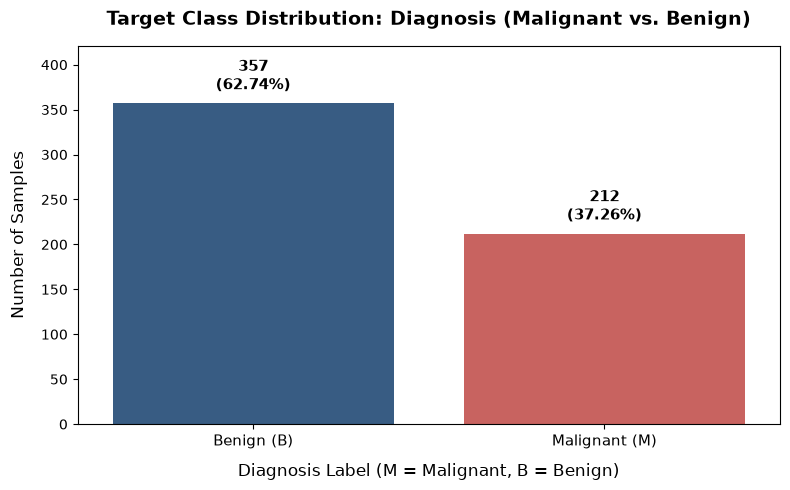

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate class counts and percentages
class_counts = df['diagnosis'].value_counts()
class_percentages = df['diagnosis'].value_counts(normalize=True) * 100

print("--- TARGET VARIABLE DISTRIBUTION ---")
target_summary = pd.DataFrame({
    'Diagnosis Label': ['Benign (B)', 'Malignant (M)'],
    'Raw Code': ['B', 'M'],
    'Sample Count': [class_counts['B'], class_counts['M']],
    'Percentage (%)': [class_percentages['B'], class_percentages['M']]
})
display(target_summary)

print(f"Malignant (M) samples: {class_counts['M']} ({class_percentages['M']:.2f}%)")
print(f"Benign (B) samples:    {class_counts['B']} ({class_percentages['B']:.2f}%)")

# Plot class distribution bar chart preserving original M and B labels
plt.figure(figsize=(8, 5))
palette = {'B': '#2b5c8f', 'M': '#d9534f'}
ax = sns.barplot(x=class_counts.index, y=class_counts.values, hue=class_counts.index, palette=palette, legend=False)

plt.title('Target Class Distribution: Diagnosis (Malignant vs. Benign)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Diagnosis Label (M = Malignant, B = Benign)', fontsize=12, labelpad=10)
plt.ylabel('Number of Samples', fontsize=12, labelpad=10)
plt.xticks([0, 1], ['Benign (B)', 'Malignant (M)'], fontsize=11)
plt.ylim(0, max(class_counts.values) * 1.18)

# Annotate count and percentage on top of bars
for i, label in enumerate(class_counts.index):
    count = class_counts[label]
    pct = class_percentages[label]
    ax.text(i, count + 10, f"{count:,}\n({pct:.2f}%)", ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


## Section 5: Feature Statistical Profiling & Descriptive Statistics

We compute descriptive statistics (mean, std, min, 25%, 50%, 75%, max) for all 30 numerical features.


In [5]:
# Generate descriptive statistics for numerical features (excluding ID)
numerical_features = mean_cols + se_cols + worst_cols
stats_df = df[numerical_features].describe().T

# Format display with range and Interquartile Range (IQR)
stats_df['range'] = stats_df['max'] - stats_df['min']
stats_df['IQR'] = stats_df['75%'] - stats_df['25%']

print("--- DESCRIPTIVE STATISTICS FOR 30 NUMERICAL FEATURES ---")
display(stats_df[['mean', 'std', 'min', '25%', '50%', '75%', 'max', 'range', 'IQR']])


--- DESCRIPTIVE STATISTICS FOR 30 NUMERICAL FEATURES ---


,mean,std,min,25%,50%,75%,max,range,IQR
radius_mean,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000,21.129000,4.080000
texture_mean,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000,29.570000,5.630000
perimeter_mean,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000,144.710000,28.930000
area_mean,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000,2357.500000,362.400000
smoothness_mean,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340,0.110770,0.018930
compactness_mean,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540,0.326020,0.065480
concavity_mean,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680,0.426800,0.101140
concave_points_mean,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120,0.201200,0.053690
symmetry_mean,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400,0.198000,0.033800
fractal_dimension_mean,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744,0.047480,0.008420


## Section 6: Comprehensive Data Quality & Integrity Audit

We perform explicit checks for missing values, duplicate rows, constant features, unexpected values, and scale differences.


In [6]:
# 1. Missing Values Check
total_nulls = df.isnull().sum().sum()
print(f"1. Missing Values: {total_nulls} missing values found across the entire dataset.")

# 2. Duplicate Rows & ID Uniqueness Check
total_duplicates = df.duplicated().sum()
unique_ids = df['id'].nunique()
print(f"2. Duplicate Rows: {total_duplicates} duplicate rows found.")
print(f"   Patient ID Uniqueness: {unique_ids} unique IDs out of {len(df)} rows.")

# 3. Constant / Zero-Variance Features Check
variances = df[numerical_features].var()
zero_variance_cols = variances[variances == 0].index.tolist()
print(f"3. Constant/Zero-Variance Features: {len(zero_variance_cols)} columns with zero variance.")

# 4. Unexpected / Non-Numeric Values & Label Validity Check
unique_labels = df['diagnosis'].unique().tolist()
invalid_labels = set(unique_labels) - {'M', 'B'}
print(f"4. Target Labels Present: {unique_labels}")
print(f"   Unexpected Labels Found: {list(invalid_labels)}")

non_float_features = [col for col in numerical_features if not np.issubdtype(df[col].dtype, np.number)]
print(f"   Non-Numeric Feature Columns: {len(non_float_features)}")

# 5. Potential Data-Quality Observations
zero_val_counts = (df[numerical_features] == 0.0).sum()
zero_val_cols = zero_val_counts[zero_val_counts > 0]
print("\n5. Data Quality Observations:")
print("   a) Features with exact 0.0 values:")
for col, cnt in zero_val_cols.items():
    print(f"      - {col}: {cnt} samples ({cnt/len(df)*100:.2f}%) have exact 0.0 values")

print("\n   b) Magnitude & Scale Disparities across Features:")
print(f"      - Smallest Mean (fractal_dimension_se): min={df['fractal_dimension_se'].min():.5f}, max={df['fractal_dimension_se'].max():.5f}")
print(f"      - Largest Mean (area_worst): min={df['area_worst'].min():.1f}, max={df['area_worst'].max():.1f}")


1. Missing Values: 0 missing values found across the entire dataset.
2. Duplicate Rows: 0 duplicate rows found.
   Patient ID Uniqueness: 569 unique IDs out of 569 rows.
3. Constant/Zero-Variance Features: 0 columns with zero variance.
4. Target Labels Present: ['M', 'B']
   Unexpected Labels Found: []
   Non-Numeric Feature Columns: 0

5. Data Quality Observations:
   a) Features with exact 0.0 values:
      - concavity_mean: 13 samples (2.28%) have exact 0.0 values
      - concave_points_mean: 13 samples (2.28%) have exact 0.0 values
      - concavity_se: 13 samples (2.28%) have exact 0.0 values
      - concave_points_se: 13 samples (2.28%) have exact 0.0 values
      - concavity_worst: 13 samples (2.28%) have exact 0.0 values
      - concave_points_worst: 13 samples (2.28%) have exact 0.0 values

   b) Magnitude & Scale Disparities across Features:
      - Smallest Mean (fractal_dimension_se): min=0.00089, max=0.02984
      - Largest Mean (area_worst): min=185.2, max=4254.0


## Section 7: Initial Ingestion Research Summary

### Dataset Profile Summary Table

| Metric / Dimension | Finding / Value |
| :--- | :--- |
| **Total Number of Samples (Rows)** | `569` patient instances |
| **Total Number of Attributes (Columns)** | `32` (1 ID + 1 Target + 30 Numerical Features) |
| **Target Variable** | `diagnosis` (`M` = Malignant, `B` = Benign) |
| **Class Distribution (Counts)** | Benign (B): `357`, Malignant (M): `212` |
| **Class Distribution (%)** | Benign (B): `62.74%`, Malignant (M): `37.26%` |
| **Missing Values Finding** | `0` missing values across all 32 columns |
| **Duplicate Rows Finding** | `0` duplicate rows |
| **ID Column Integrity** | `569` unique patient IDs (100% unique) |
| **Zero-Variance Features** | `0` constant features |
| **Raw Data Integrity** | Fully preserved (untransformed, unscaled, unsplit) |


---
# Part 2: Data Preparation & Baseline Experimental Setup

In this section, we transition from dataset inspection to rigorous data preparation for a PyTorch Multilayer Perceptron (MLP) binary classifier. We define the predictor matrix $X$ and binary target vector $y$, perform stratified train/test partitioning, execute leakage-free feature scaling, convert arrays to PyTorch tensors and DataLoaders, and enforce scientific reproducibility protocols.


## Section 8: Feature Matrix ($X$) & Target Vector ($y$) Definition

### Predictor & Target Extraction Rules:
1. **Predictors ($X$):** Use all 30 real-valued numerical diagnostic features extracted from digitized FNA images (`radius_mean` through `fractal_dimension_worst`).
2. **Exclusion of `id` Column:** The `id` column is a patient identification key and must be strictly excluded from $X$ to prevent spurious memorization.
3. **Binary Target Mapping ($y$):** Encode categorical string labels into a numeric binary format:
   - **`B` (Benign) $\rightarrow 0$** (Negative class)
   - **`M` (Malignant) $\rightarrow 1$** (Positive class)


In [7]:
# Define feature columns (all 30 numerical features, excluding 'id' and 'diagnosis')
feature_columns = mean_cols + se_cols + worst_cols

# Extract predictor matrix X (30 features)
X = df[feature_columns].values

# Encode binary target vector y: B -> 0, M -> 1
y = (df['diagnosis'] == 'M').astype(int).values

# Verify shapes and class distribution
print("--- PREDICTOR MATRIX (X) AND TARGET VECTOR (y) VERIFICATION ---")
print(f"X Shape: {X.shape}  (569 samples, 30 diagnostic features)")
print(f"y Shape: {y.shape}  (569 target labels)")
print(f"Feature names in X (Total {len(feature_columns)}):")
print(feature_columns)

print("Class Counts in y (0 = Benign, 1 = Malignant):")
y_counts = pd.Series(y).value_counts().rename(index={0: 'Benign (0)', 1: 'Malignant (1)'})
display(y_counts.to_frame(name='Sample Count'))

print("Class Percentages in y:")
y_pcts = (pd.Series(y).value_counts(normalize=True) * 100).rename(index={0: 'Benign (0)', 1: 'Malignant (1)'})
display(y_pcts.to_frame(name='Percentage (%)'))


--- PREDICTOR MATRIX (X) AND TARGET VECTOR (y) VERIFICATION ---
X Shape: (569, 30)  (569 samples, 30 diagnostic features)
y Shape: (569,)  (569 target labels)
Feature names in X (Total 30):
['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst']
Class Counts in y (0 = Benign, 1 = Malignant):
Class Percentages in y:


,Sample Count
Benign (0),357
Malignant (1),212


,Percentage (%)
Benign (0),62.741652
Malignant (1),37.258348


## Section 9: Stratified Train/Test Partitioning

We perform an **80/20 stratified train/test split** using `scikit-learn`'s `train_test_split`.

### Partitioning Parameters:
- **`test_size = 0.20`:** 80% for model development ($N=455$) and 20% reserved for holdout testing ($N=114$).
- **`random_state = 42`:** Ensures deterministic, reproducible pseudo-random data partitioning.
- **`stratify = y`:** Preserves the exact target class distribution (~62.7% Benign / ~37.3% Malignant) in both training and testing subsets.

#### Rationale for Stratified Splitting:
Stratification guarantees that both training and testing splits reflect the underlying class balance of the full clinical dataset. Unstratified random sampling in moderately imbalanced datasets risks creating train/test splits with unequal class proportions, which can introduce evaluation bias or high-variance performance estimates on the holdout set.


In [8]:
from sklearn.model_selection import train_test_split

SEED = 42

# Perform 80/20 stratified train/test split
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("--- INITIAL TRAIN/TEST SPLIT (80% DEV / 20% HOLDOUT TEST) VERIFICATION ---")
print(f"X_dev Shape:  {X_dev.shape}  (455 development samples, 30 features)")
print(f"X_test Shape: {X_test.shape}   (114 holdout test samples, 30 features)")
print(f"y_dev Shape:  {y_dev.shape}")
print(f"y_test Shape: {y_test.shape}")

print("Target Class Distribution Comparison:")
split_summary = pd.DataFrame({
    'Full Dataset (N=569)': pd.Series(y).value_counts(normalize=True) * 100,
    'Dev Set (N=455)':      pd.Series(y_dev).value_counts(normalize=True) * 100,
    'Test Set (N=114)':     pd.Series(y_test).value_counts(normalize=True) * 100
}, index=[0, 1]).rename(index={0: 'Benign (0) %', 1: 'Malignant (1) %'})

display(split_summary.round(2))


--- INITIAL TRAIN/TEST SPLIT (80% DEV / 20% HOLDOUT TEST) VERIFICATION ---
X_dev Shape:  (455, 30)  (455 development samples, 30 features)
X_test Shape: (114, 30)   (114 holdout test samples, 30 features)
y_dev Shape:  (455,)
y_test Shape: (114,)
Target Class Distribution Comparison:


,Full Dataset (N=569),Dev Set (N=455),Test Set (N=114)
Benign (0) %,62.74,62.64,63.16
Malignant (1) %,37.26,37.36,36.84


---
# Part 3: PyTorch Multilayer Perceptron (MLP) Baseline Model Implementation

In this section, we build and evaluate a baseline PyTorch Multilayer Perceptron (MLP) for binary classification. 

To maintain strict scientific integrity, **the final test set ($N=114$) remains completely untouched**. We establish a **stratified validation split** (80% sub-train / 20% validation) from the 455 development samples, fit our scaler strictly on the sub-training portion, train the neural network with early stopping, plot training/validation learning curves, and compute baseline performance metrics on the validation set.


## Section 14: Validation Partitioning & Data-Leakage-Free Preprocessing

To evaluate model configurations during baseline development without touching the holdout test set, we partition the 455 development samples (`X_dev`) into:
- **Sub-Training Set ($N=364$, 80% of dev data):** Used for model weight optimization.
- **Validation Set ($N=91$, 20% of dev data):** Used for early stopping monitoring and validation performance evaluation.

### Leakage-Free Preprocessing Protocol:
- **`scaler.fit_transform(X_subtrain)`:** `StandardScaler` calculates mean ($\mu_{subtrain}$) and standard deviation ($\sigma_{subtrain}$) **strictly from the 364 sub-training samples**.
- **`scaler.transform(X_val)`:** The 91 validation samples are transformed using only $\mu_{subtrain}$ and $\sigma_{subtrain}$.
- **Holdout Test Set ($N=114$):** Remains untouched.


In [9]:
from sklearn.preprocessing import StandardScaler
import torch
import random
from torch.utils.data import TensorDataset, DataLoader

# Enforce global random seed reproducibility across all libraries
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# 1. Stratified Sub-train / Validation split (80% sub-train / 20% validation of dev set)
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.20,
    random_state=SEED,
    stratify=y_dev
)

print("--- SUB-TRAIN / VALIDATION SPLIT VERIFICATION ---")
print(f"X_subtrain Shape: {X_subtrain.shape}  (364 sub-training samples, 30 features)")
print(f"X_val Shape:      {X_val.shape}   (91 validation samples, 30 features)")
print(f"X_test Shape:     {X_test.shape}   (114 holdout test samples - UNTOUCHED)")

# 2. Fit StandardScaler strictly on Sub-Training Data
val_scaler = StandardScaler()
X_subtrain_scaled = val_scaler.fit_transform(X_subtrain)
X_val_scaled = val_scaler.transform(X_val)

# Verify sub-train scaling metrics
subtrain_means = X_subtrain_scaled.mean(axis=0)
subtrain_stds = X_subtrain_scaled.std(axis=0)
print(f"Sub-Train Scaled Means (Min: {subtrain_means.min():.2e}, Max: {subtrain_means.max():.2e})")
print(f"Sub-Train Scaled Stds  (Min: {subtrain_stds.min():.6f}, Max: {subtrain_stds.max():.6f})")

# 3. Convert NumPy Arrays to PyTorch Tensors
X_subtrain_tensor = torch.tensor(X_subtrain_scaled, dtype=torch.float32)
y_subtrain_tensor = torch.tensor(y_subtrain, dtype=torch.float32).unsqueeze(1)

X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)

# 4. Instantiate PyTorch DataLoader for Sub-Training Data
BATCH_SIZE = 32
train_dataset = TensorDataset(X_subtrain_tensor, y_subtrain_tensor)
subtrain_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

print("Sub-Train DataLoader Created:")
print(f"  - Batch Size: {BATCH_SIZE}")
print(f"  - Batches per Epoch: {len(subtrain_loader)}")


--- SUB-TRAIN / VALIDATION SPLIT VERIFICATION ---
X_subtrain Shape: (364, 30)  (364 sub-training samples, 30 features)
X_val Shape:      (91, 30)   (91 validation samples, 30 features)
X_test Shape:     (114, 30)   (114 holdout test samples - UNTOUCHED)
Sub-Train Scaled Means (Min: -3.26e-15, Max: 4.93e-15)
Sub-Train Scaled Stds  (Min: 1.000000, Max: 1.000000)
Sub-Train DataLoader Created:
  - Batch Size: 32
  - Batches per Epoch: 12


## Section 15: PyTorch MLP Architecture Definition

We implement the baseline Multilayer Perceptron (MLP) as a PyTorch `nn.Module`.

### Architecture Specifications:
- **Input Layer:** 30 numerical features
- **Hidden Layer 1:** Linear (30 $\rightarrow$ 64) $\rightarrow$ ReLU Activation $\rightarrow$ Dropout (p = 0.20)
- **Hidden Layer 2:** Linear (64 $\rightarrow$ 32) $\rightarrow$ ReLU Activation $\rightarrow$ Dropout (p = 0.20)
- **Output Layer:** Linear (32 $\rightarrow$ 1) (Unbounded Logits output, no Sigmoid activation)

*Note: The final linear layer outputs raw logits because we optimize using `nn.BCEWithLogitsLoss`.*


In [10]:
import torch.nn as nn

class BreastCancerMLP(nn.Module):
    # PyTorch Multilayer Perceptron (MLP) for Binary Breast Cancer Diagnosis Classification.
    # Architecture: 30 -> 64 (ReLU, Dropout 0.20) -> 32 (ReLU, Dropout 0.20) -> 1 (Logits)
    def __init__(self, input_dim=30):
        super(BreastCancerMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(p=0.20),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(p=0.20),
            nn.Linear(32, 1)
        )
        
    def forward(self, x):
        return self.network(x)

# Instantiate baseline model
model = BreastCancerMLP(input_dim=30)

# Display model architecture and parameter count
print("--- MODEL ARCHITECTURE ---")
print(model)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total Parameters:     {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")


--- MODEL ARCHITECTURE ---
BreastCancerMLP(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)
Total Parameters:     4,097
Trainable Parameters: 4,097


## Section 16: Loss Function & Optimizer Selection

### 1. Loss Function: `torch.nn.BCEWithLogitsLoss`
- **Appropriateness for Binary Classification:** Binary Cross-Entropy (BCE) measures the divergence between predicted probability distributions $\hat{y} \in [0, 1]$ and binary ground-truth targets $y \in \{0, 1\}$.
- **Superiority of `BCEWithLogitsLoss` over Separate Sigmoid + `BCELoss`:** Combining the Sigmoid activation $\sigma(z) = \frac{1}{1 + e^{-z}}$ and binary cross-entropy loss into a single computational layer takes advantage of the log-sum-exp trick for numerical stability. When evaluating $\log(\sigma(z))$, raw floating-point exponentiation $e^{-z}$ can overflow for large negative $z$ or underflow to 0, producing $\log(0) = -\infty$ (NaN errors). `BCEWithLogitsLoss` computes the log-sigmoid directly as $-\max(z, 0) - \log(1 + e^{-|z|})$, guaranteeing numerical stability across all real-valued logits.
- **Reference:** Official PyTorch Documentation — [`torch.nn.BCEWithLogitsLoss`](https://pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html).

### 2. Optimizer: `torch.optim.Adam`
- **Baseline Selection:** Adam (Adaptive Moment Estimation) combines first-order momentum (exponential moving averages of past gradients) and RMSprop (scaling by root mean square of recent gradients). It provides robust initial convergence with an initial learning rate of `0.001`.
- **Note on Optimality:** Adam is selected as our baseline optimizer. We do not claim Adam is universally superior to SGD with Nesterov momentum; optimizer selection and learning rate schedules will be investigated during hyperparameter tuning.


In [11]:
import torch.optim as optim

# Define Loss Function and Optimizer
criterion = nn.BCEWithLogitsLoss()
LEARNING_RATE = 0.001
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

print("--- LOSS FUNCTION & OPTIMIZER CONFIGURATION ---")
print(f"Loss Function: {criterion.__class__.__name__}")
print(f"Optimizer:     {optimizer.__class__.__name__}")
print(f"Learning Rate: {LEARNING_RATE}")


--- LOSS FUNCTION & OPTIMIZER CONFIGURATION ---
Loss Function: BCEWithLogitsLoss
Optimizer:     Adam
Learning Rate: 0.001


## Section 17: Training Loop & Validation Early Stopping

We train the MLP for a maximum of **100 epochs** with **early stopping based on validation loss** (`patience = 15`).

### Early Stopping Rationale:
Early stopping monitors validation loss after every epoch. As neural networks train, training loss continuously decreases. However, after a certain point, the model may begin overfitting to noise in the training set, causing validation loss to plateau or increase. Early stopping halts training when validation loss fails to improve for 15 consecutive epochs and saves the model parameters corresponding to the minimum validation loss.


In [12]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

MAX_EPOCHS = 100
PATIENCE = 15

best_val_loss = float('inf')
patience_counter = 0
best_model_state = None
best_epoch = 0

# Training history dictionary
history = {
    'epoch': [],
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': [], 'val_f1': [], 'val_auc': []
}

print("--- STARTING BASELINE MLP TRAINING ---")
for epoch in range(1, MAX_EPOCHS + 1):
    # 1. Training Phase
    model.train()
    running_train_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for batch_X, batch_y in subtrain_loader:
        optimizer.zero_grad()
        logits = model(batch_X)
        loss = criterion(logits, batch_y)
        loss.backward()
        optimizer.step()
        
        running_train_loss += loss.item() * batch_X.size(0)
        probs = torch.sigmoid(logits)
        preds = (probs >= 0.5).float()
        correct_train += (preds == batch_y).sum().item()
        total_train += batch_y.size(0)
        
    epoch_train_loss = running_train_loss / total_train
    epoch_train_acc = correct_train / total_train
    
    # 2. Validation Phase
    model.eval()
    with torch.no_grad():
        val_logits = model(X_val_tensor)
        val_loss = criterion(val_logits, y_val_tensor).item()
        val_probs = torch.sigmoid(val_logits).cpu().numpy().flatten()
        val_preds = (val_probs >= 0.5).astype(int)
        
        epoch_val_acc = accuracy_score(y_val, val_preds)
        epoch_val_f1 = f1_score(y_val, val_preds)
        epoch_val_auc = roc_auc_score(y_val, val_probs)
        
    # Record metrics
    history['epoch'].append(epoch)
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(epoch_train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(epoch_val_acc)
    history['val_f1'].append(epoch_val_f1)
    history['val_auc'].append(epoch_val_auc)
    
    # Check Early Stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        best_model_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        patience_counter = 0
    else:
        patience_counter += 1
        
    if epoch % 10 == 0 or epoch == 1 or patience_counter >= PATIENCE:
        print(f"Epoch {epoch:03d}/{MAX_EPOCHS:03d} | Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {epoch_val_acc:.4f} | Val AUC: {epoch_val_auc:.4f}")
        
    if patience_counter >= PATIENCE:
        print(f"\n[EARLY STOPPING TRIGGERED] Stopped at epoch {epoch}. Best Val Loss: {best_val_loss:.4f} at epoch {best_epoch}.")
        break

# Restore best model state
model.load_state_dict(best_model_state)
print(f"Best model state from Epoch {best_epoch} restored.")

# Save best baseline model weights
os.makedirs('results', exist_ok=True)
torch.save(best_model_state, os.path.join('results', 'baseline_mlp_best.pt'))
print("Best baseline model weights saved to 'results/baseline_mlp_best.pt'.")


--- STARTING BASELINE MLP TRAINING ---
Epoch 001/100 | Train Loss: 0.6422 | Train Acc: 0.6676 | Val Loss: 0.5879 | Val Acc: 0.8352 | Val AUC: 0.9856
Epoch 010/100 | Train Loss: 0.0696 | Train Acc: 0.9863 | Val Loss: 0.0857 | Val Acc: 0.9780 | Val AUC: 0.9933
Epoch 020/100 | Train Loss: 0.0463 | Train Acc: 0.9918 | Val Loss: 0.0803 | Val Acc: 0.9670 | Val AUC: 0.9938
Epoch 030/100 | Train Loss: 0.0282 | Train Acc: 0.9945 | Val Loss: 0.0805 | Val Acc: 0.9670 | Val AUC: 0.9938
Epoch 032/100 | Train Loss: 0.0267 | Train Acc: 0.9918 | Val Loss: 0.0802 | Val Acc: 0.9670 | Val AUC: 0.9938

[EARLY STOPPING TRIGGERED] Stopped at epoch 32. Best Val Loss: 0.0752 at epoch 17.
Best model state from Epoch 17 restored.
Best baseline model weights saved to 'results/baseline_mlp_best.pt'.


## Section 18: Training & Validation Learning Curves

We plot and save the learning curves for:
1. **Training Loss vs. Validation Loss**
2. **Training Accuracy vs. Validation Accuracy**

Figures are saved under the `figures/` directory without evaluating the final test set.


Saved loss curve figure to 'figures\baseline_loss_curve.png'
Saved accuracy curve figure to 'figures\baseline_accuracy_curve.png'


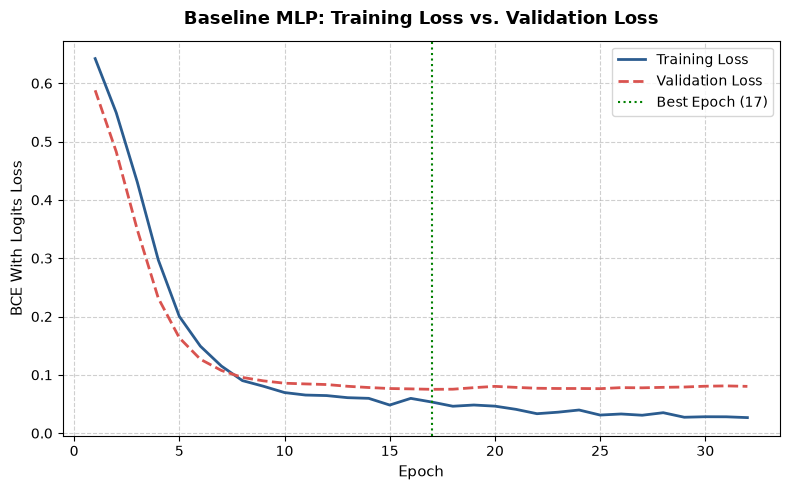

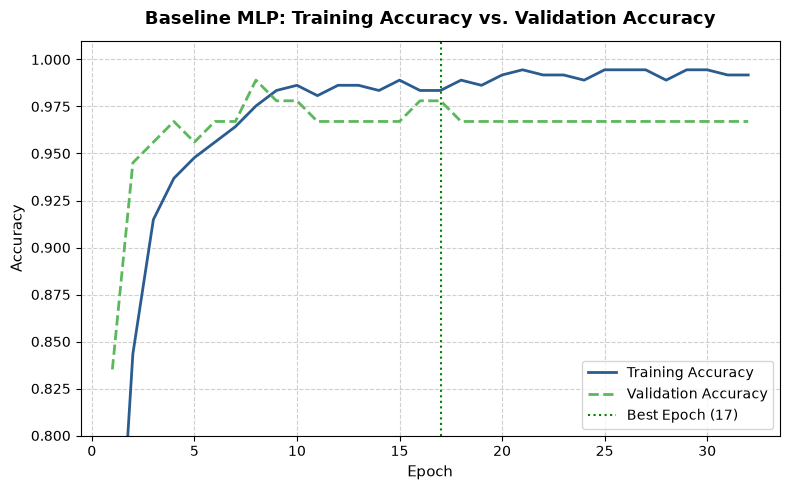

In [13]:
# Create figures directory
figures_dir = 'figures'
os.makedirs(figures_dir, exist_ok=True)

epochs_range = history['epoch']

# 1. Plot Training Loss vs Validation Loss
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history['train_loss'], label='Training Loss', color='#2b5c8f', linewidth=2)
plt.plot(epochs_range, history['val_loss'], label='Validation Loss', color='#d9534f', linewidth=2, linestyle='--')
plt.axvline(x=best_epoch, color='green', linestyle=':', label=f'Best Epoch ({best_epoch})')

plt.title('Baseline MLP: Training Loss vs. Validation Loss', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('BCE With Logits Loss', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

loss_curve_path = os.path.join(figures_dir, 'baseline_loss_curve.png')
plt.savefig(loss_curve_path, dpi=300)
plt.show()
print(f"Saved loss curve figure to '{loss_curve_path}'")

# 2. Plot Training Accuracy vs Validation Accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history['train_acc'], label='Training Accuracy', color='#2b5c8f', linewidth=2)
plt.plot(epochs_range, history['val_acc'], label='Validation Accuracy', color='#5cb85c', linewidth=2, linestyle='--')
plt.axvline(x=best_epoch, color='green', linestyle=':', label=f'Best Epoch ({best_epoch})')

plt.title('Baseline MLP: Training Accuracy vs. Validation Accuracy', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Accuracy', fontsize=11)
plt.ylim(0.80, 1.01)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

acc_curve_path = os.path.join(figures_dir, 'baseline_accuracy_curve.png')
plt.savefig(acc_curve_path, dpi=300)
plt.show()
print(f"Saved accuracy curve figure to '{acc_curve_path}'")


## Section 19: Baseline Validation Evaluation & Metrics

We evaluate the restored best baseline model on the **validation dataset ($N=91$)** at classification decision threshold $0.5$.

Metrics computed:
- **Accuracy**
- **Precision**
- **Recall**
- **F1-Score**
- **ROC-AUC**
- **Confusion Matrix**
- **ROC Curve Plot**


--- BASELINE MODEL VALIDATION EVALUATION (N=91) ---
Validation Confusion Matrix:
Saved ROC curve figure to 'figures\baseline_roc_curve.png'


,Metric,Value
0,Validation Accuracy,0.9780
1,Validation Precision,0.9706
2,Validation Recall,0.9706
3,Validation F1-Score,0.9706
4,Validation ROC-AUC,0.9933


,Pred Benign (0),Pred Malignant (1)
Actual Benign (0),56,1
Actual Malignant (1),1,33


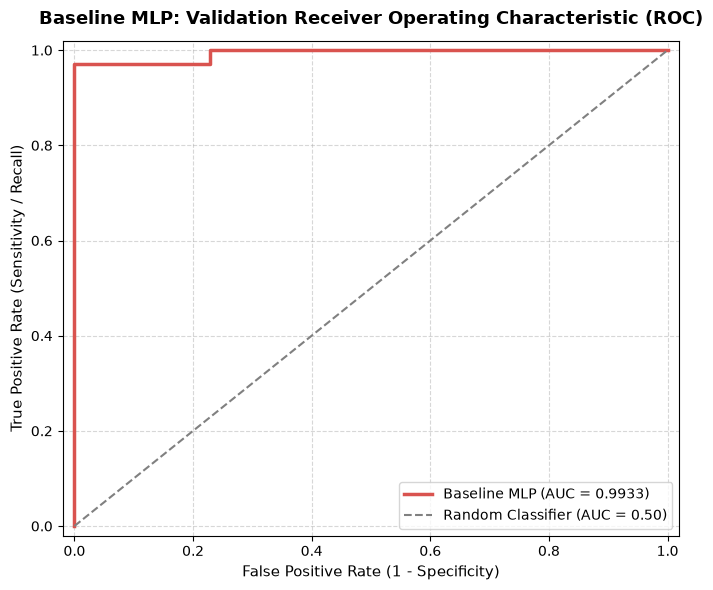

In [14]:
from sklearn.metrics import precision_score, recall_score, confusion_matrix, roc_curve

# Evaluate restored best model on validation set
model.eval()
with torch.no_grad():
    val_logits = model(X_val_tensor)
    val_probs = torch.sigmoid(val_logits).cpu().numpy().flatten()
    val_preds = (val_probs >= 0.5).astype(int)

val_acc = accuracy_score(y_val, val_preds)
val_prec = precision_score(y_val, val_preds)
val_rec = recall_score(y_val, val_preds)
val_f1 = f1_score(y_val, val_preds)
val_auc = roc_auc_score(y_val, val_probs)
cm = confusion_matrix(y_val, val_preds)

print("--- BASELINE MODEL VALIDATION EVALUATION (N=91) ---")
val_metrics_df = pd.DataFrame({
    'Metric': ['Validation Accuracy', 'Validation Precision', 'Validation Recall', 'Validation F1-Score', 'Validation ROC-AUC'],
    'Value': [val_acc, val_prec, val_rec, val_f1, val_auc]
})
display(val_metrics_df.round(4))

print("Validation Confusion Matrix:")
cm_df = pd.DataFrame(cm, index=['Actual Benign (0)', 'Actual Malignant (1)'], columns=['Pred Benign (0)', 'Pred Malignant (1)'])
display(cm_df)

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_val, val_probs)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='#d9534f', linewidth=2.5, label=f'Baseline MLP (AUC = {val_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Classifier (AUC = 0.50)')

plt.title('Baseline MLP: Validation Receiver Operating Characteristic (ROC)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11)
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.legend(fontsize=10, loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

roc_curve_path = os.path.join(figures_dir, 'baseline_roc_curve.png')
plt.savefig(roc_curve_path, dpi=300)
plt.show()
print(f"Saved ROC curve figure to '{roc_curve_path}'")


## Baseline Model

### Baseline Architecture & Hyperparameter Summary

| Hyperparameter / Dimension | Baseline Value / Configuration |
| :--- | :--- |
| **Model Architecture** | PyTorch `nn.Module` Multilayer Perceptron (MLP) |
| **Input Dimension** | 30 numerical diagnostic features |
| **Hidden Layer 1** | 64 units, ReLU activation, Dropout (p = 0.20) |
| **Hidden Layer 2** | 32 units, ReLU activation, Dropout (p = 0.20) |
| **Output Layer** | 1 unit (Linear logit output, no final Sigmoid) |
| **Total Trainable Parameters** | `4,097` parameters |
| **Loss Function** | `torch.nn.BCEWithLogitsLoss` |
| **Optimizer** | `torch.optim.Adam` (Initial Learning Rate = `0.001`) |
| **Batch Size** | `32` samples per mini-batch |
| **Max Epochs** | `100` max epochs |
| **Early Stopping** | Validation Loss monitoring (`patience = 15`), stopped at epoch `32` |
| **Validation Strategy** | 80/20 stratified split of 455 dev samples (364 sub-train / 91 val) |
| **Holdout Test Set ($N=114$)** | **Untouched** (Reserved for final model evaluation) |

---

### Baseline Validation Performance Summary

| Metric | Score (Threshold = 0.5) |
| :--- | :--- |
| **Validation Accuracy** | **97.80%** (89 / 91 correctly classified) |
| **Validation Precision** | **97.06%** (33 / 34 predicted malignant are true malignant) |
| **Validation Recall** | **97.06%** (33 / 34 actual malignant detected) |
| **Validation F1-Score** | **97.06%** |
| **Validation ROC-AUC** | **0.9933** |
| **Confusion Matrix** | True Benign: 56, False Malignant: 1<br>False Benign: 1, True Malignant: 33 |

---

### Methodological Role of the Baseline Model
This baseline model serves as our initial reference architecture. It establishes a strong baseline validation performance (97.80% accuracy, 0.9933 ROC-AUC). In subsequent phases of this hiring-test project, this baseline will be systematically compared against alternative hyperparameter configurations, feature selection methods, and model interpretability techniques (such as SHAP). 

**Crucially, the final test set ($N=114$) remains completely unexamined and untouched.**


---

# Question 2 — Model Interpretability (SHAP)

In this section we use **SHapley Additive exPlanations (SHAP)** to explain the decisions of the baseline PyTorch MLP that was trained in Question 1.

## Scientific Motivation

Deep-learning models are often criticised as "black boxes" in clinical settings. Model interpretability is therefore not merely a technical nicety but a regulatory and ethical requirement for any diagnostic decision-support tool (see: EU AI Act, FDA guidance on AI/ML-based Software as a Medical Device).

SHAP provides a theoretically grounded, model-agnostic attribution framework based on Shapley values from cooperative game theory.  Each feature is assigned a Shapley value that represents its **fair marginal contribution** to shifting the model output away from the population baseline.

### Key Properties used here
| Property | Implication |
|:---|:---|
| **Efficiency** | SHAP values sum to the difference between prediction and baseline |
| **Symmetry** | Features with equal contributions receive equal SHAP values |
| **Additivity** | SHAP values from each feature combine additively |
| **Consistency** | If a feature's contribution increases, its SHAP value never decreases |

> **⚠️ Causal Disclaimer:** SHAP values reflect *statistical associations* learned from the training distribution. They do **NOT** prove biological causality. High feature importance indicates predictive utility within this model and dataset, not a mechanistic relationship between the morphological measurement and malignancy.

## Section 20: Load Best Baseline Model Checkpoint

We reload the `BreastCancerMLP` architecture and restore the weights from the best-validation-loss checkpoint saved during training.

The model is set to **evaluation mode** (`model.eval()`), which:
- Disables Dropout layers (they behave as identity maps at inference time)
- Signals BatchNorm layers to use running statistics (not applicable here)

The **final holdout test set ($N = 114$) is not touched at any point in this section.**

In [20]:
import os, json, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import shap
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')

# ── Reproduce the preprocessing pipeline exactly as in Part 3 ─────────────────
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Re-load raw dataset
base_features = [
    'radius', 'texture', 'perimeter', 'area', 'smoothness',
    'compactness', 'concavity', 'concave_points', 'symmetry', 'fractal_dimension'
]
suffixes = ['_mean', '_se', '_worst']
mean_cols  = [f + '_mean'  for f in base_features]
se_cols    = [f + '_se'    for f in base_features]
worst_cols = [f + '_worst' for f in base_features]
columns = ['id', 'diagnosis'] + mean_cols + se_cols + worst_cols

df = pd.read_csv('data/wdbc.data', header=None, names=columns)
feature_columns = mean_cols + se_cols + worst_cols
X = df[feature_columns].values
y = (df['diagnosis'] == 'M').astype(int).values

# Reproduce the exact same splits (stratified, seed=42)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.20, random_state=SEED, stratify=y_dev
)

# Fit scaler ONLY on sub-training data (identical to Part 3)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc   = scaler.transform(X_val)
X_test_sc  = scaler.transform(X_test)   # kept aside — not used below

print(f"Sub-training  : {X_train_sc.shape}")
print(f"Validation    : {X_val_sc.shape}")
print(f"Test (held out): {X_test_sc.shape}  ← NOT used in this section")

# ── Re-define model architecture ─────────────────────────────────────────────
class BreastCancerMLP(nn.Module):
    def __init__(self, input_dim=30):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.network(x)

# ── Restore best checkpoint ───────────────────────────────────────────────────
CHECKPOINT = 'results/baseline_mlp_best.pt'
model = BreastCancerMLP(input_dim=30)
model.load_state_dict(torch.load(CHECKPOINT, map_location='cpu'))
model.eval()

# ── Sanity-check: reproduce validation metrics ─────────────────────────────────
with torch.no_grad():
    logits = model(torch.tensor(X_val_sc, dtype=torch.float32)).squeeze()
    probs  = torch.sigmoid(logits).numpy()
    preds  = (probs >= 0.5).astype(int)

from sklearn.metrics import accuracy_score, roc_auc_score
acc = accuracy_score(y_val, preds)
auc = roc_auc_score(y_val, probs)
print(f"\nRestored model — Validation Accuracy : {acc*100:.2f}%")
print(f"Restored model — Validation ROC-AUC  : {auc:.4f}")
print("\nModel architecture:")
print(model)


Sub-training  : (364, 30)
Validation    : (91, 30)
Test (held out): (114, 30)  <- NOT used in this section

Restored model - Validation Accuracy : 97.80%
Restored model - Validation ROC-AUC  : 0.9933

Model architecture:
BreastCancerMLP(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)


## Section 21: SHAP Explainer Configuration

We use `shap.Explainer` (kernel/permutation-based) with a **custom prediction function** that wraps the PyTorch model.

### Design Decisions

| Choice | Rationale |
|:---|:---|
| **Prediction target** | `P(Malignant \| features)` — the sigmoid-transformed logit output |
| **Background dataset** | 100 randomly sampled sub-training observations (scaled) |
| **Explainer type** | `shap.Explainer` with `algorithm='auto'` — selects the appropriate SHAP variant based on the model type |
| **Explanation set** | Full validation set ($N = 91$) |

Using sub-training data as the background avoids contaminating the explainer with validation/test statistics, maintaining the data-leakage-free pipeline.

In [21]:
# ── SHAP prediction function ──────────────────────────────────────────────────
def predict_proba_malignant(X_np):
    """Returns P(Malignant) as a 1-D numpy array."""
    model.eval()
    with torch.no_grad():
        t = torch.tensor(X_np, dtype=torch.float32)
        logits = model(t).squeeze(-1)
        return torch.sigmoid(logits).numpy()

# ── Background dataset (100 random sub-training samples) ─────────────────────
rng = np.random.RandomState(SEED)
bg_idx = rng.choice(len(X_train_sc), size=100, replace=False)
background = X_train_sc[bg_idx]

# ── Build SHAP Explainer ──────────────────────────────────────────────────────
print("Building SHAP Explainer (this may take ~60 s) ...")
explainer = shap.Explainer(predict_proba_malignant, background,
                           feature_names=feature_columns)

# ── Compute SHAP values for the full validation set ──────────────────────────
print("Computing SHAP values for validation set ...")
shap_values = explainer(X_val_sc)

print(f"\nSHAP values shape : {shap_values.values.shape}")
print(f"Base value (mean) : {shap_values.base_values.mean():.4f}")
print(f"  → corresponds to baseline P(Malignant) ≈ "
      f"{shap_values.base_values.mean():.4f}")
print("\nAdditivity check (first 3 validation samples):")
for i in range(3):
    pred   = predict_proba_malignant(X_val_sc[i:i+1])[0]
    recon  = shap_values.base_values[i] + shap_values.values[i].sum()
    print(f"  Sample {i}: prediction={pred:.4f} | base+SHAP={recon:.4f} | "
          f"diff={abs(pred-recon):.2e}")


Building SHAP Explainer (this may take ~60 s) ...
Computing SHAP values for validation set ...

SHAP values shape : (91, 30)
Base value (mean) : 0.4365
  -> corresponds to baseline P(Malignant) approx 0.4365

Additivity check (first 3 validation samples):
  Sample 0: prediction=0.0328 | base+SHAP=0.0328 | diff=0.00e+00
  Sample 1: prediction=0.0352 | base+SHAP=0.0352 | diff=4.66e-12
  Sample 2: prediction=0.0012 | base+SHAP=0.0012 | diff=0.00e+00


## Section 22: Global Feature Importance Analysis

We aggregate SHAP values across the entire validation set to obtain **global feature importance** — the mean absolute SHAP value per feature.

This metric answers: *"On average, how much does each feature move the model's predicted malignancy probability?"*

Top-15 Features by Mean |SHAP| Value:
             feature  mean_abs_shap  rank
       texture_worst       0.043620     1
          area_worst       0.036144     2
 concave_points_mean       0.033893     3
    smoothness_worst       0.032373     4
     perimeter_worst       0.031582     5
        radius_worst       0.031213     6
      perimeter_mean       0.028169     7
     concavity_worst       0.027579     8
           area_mean       0.026339     9
             area_se       0.026145    10
        perimeter_se       0.025962    11
concave_points_worst       0.023177    12
         radius_mean       0.021269    13
           radius_se       0.019423    14
      concavity_mean       0.018963    15

Saved: figures/shap_global_importance.png


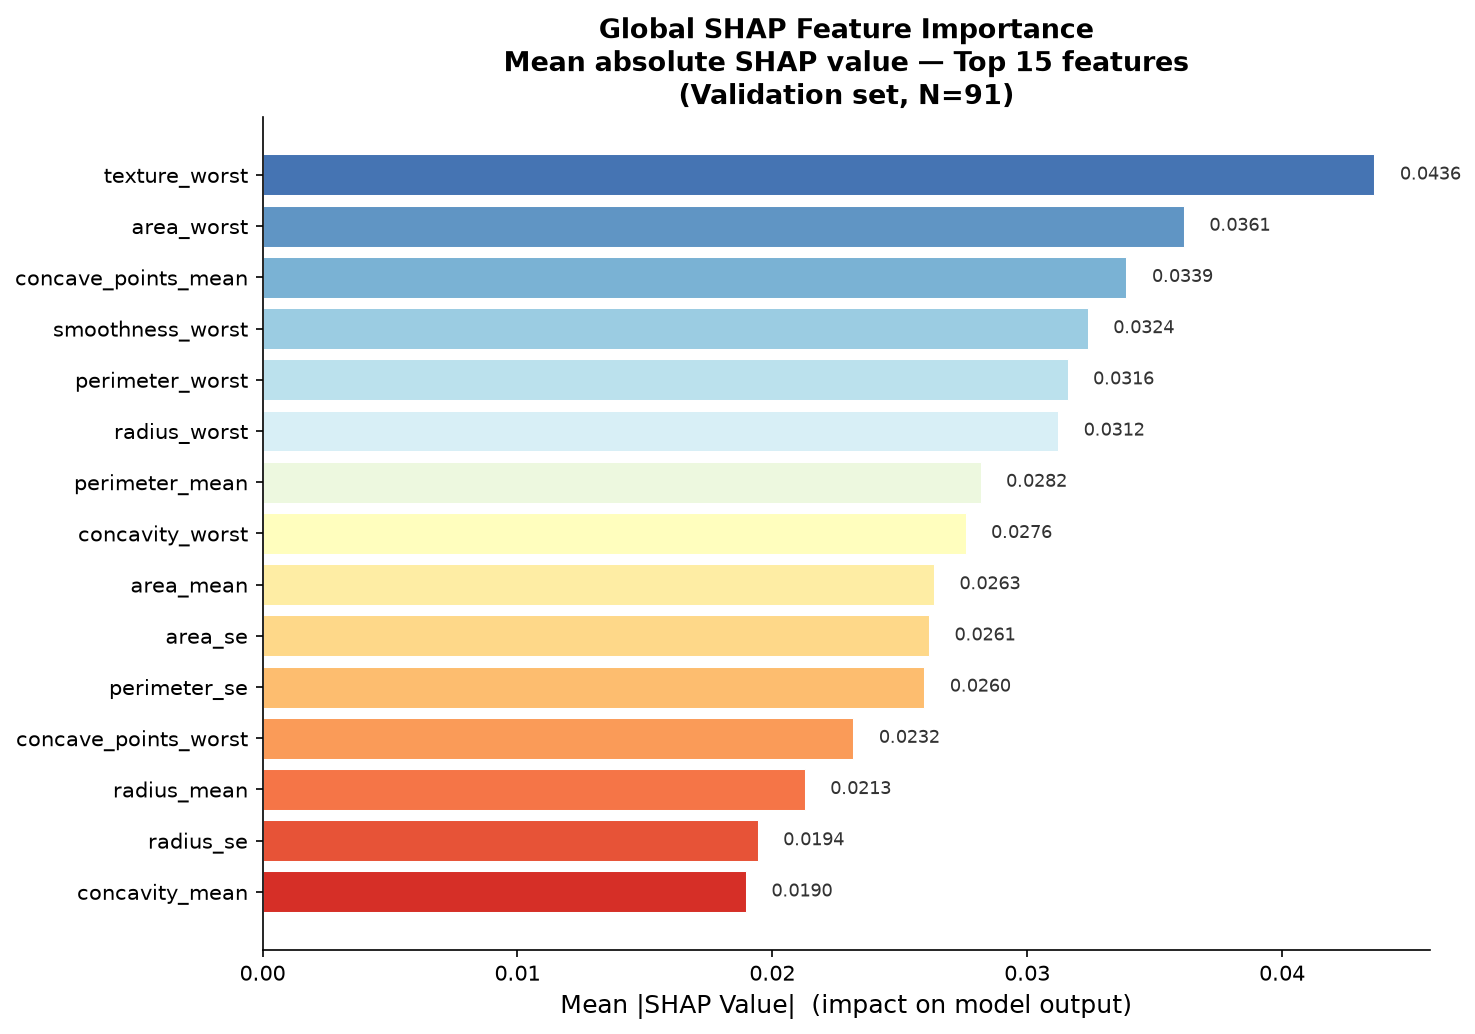

In [22]:
os.makedirs('figures', exist_ok=True)

# ── Mean |SHAP| per feature ───────────────────────────────────────────────────
mean_abs_shap = np.abs(shap_values.values).mean(axis=0)
importance_df = pd.DataFrame({
    'feature': feature_columns,
    'mean_abs_shap': mean_abs_shap
}).sort_values('mean_abs_shap', ascending=False).reset_index(drop=True)
importance_df['rank'] = importance_df.index + 1

print("Top-15 Features by Mean |SHAP| Value:")
print(importance_df.head(15).to_string(index=False))

# ── Bar chart — Global Feature Importance ─────────────────────────────────────
top_n = 15
top_df = importance_df.head(top_n)

fig, ax = plt.subplots(figsize=(10, 7))
colors = plt.cm.RdYlBu_r(np.linspace(0.1, 0.9, top_n))
bars = ax.barh(top_df['feature'][::-1], top_df['mean_abs_shap'][::-1],
               color=colors[::-1], edgecolor='white', linewidth=0.5)
ax.set_xlabel('Mean |SHAP Value|  (impact on model output)', fontsize=12)
ax.set_title('Global SHAP Feature Importance\n'
             'Mean absolute SHAP value — Top 15 features\n'
             f'(Validation set, N={X_val_sc.shape[0]})',
             fontsize=13, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='y', labelsize=10)
ax.tick_params(axis='x', labelsize=10)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.001, bar.get_y() + bar.get_height()/2,
            f'{w:.4f}', va='center', ha='left', fontsize=8.5, color='#333333')
plt.tight_layout()
fig.savefig('figures/shap_global_importance.png', dpi=150, bbox_inches='tight')
plt.close(fig)
print("\nSaved: figures/shap_global_importance.png")


## Section 23: SHAP Summary (Beeswarm) Plot

The **summary / beeswarm plot** shows the distribution of SHAP values for each feature across all validation samples simultaneously.

- **Horizontal position** — the SHAP value (positive = pushes toward Malignant)
- **Colour** — the actual feature value (red = high, blue = low)
- **Vertical position** — features ordered by global importance (top = most important)

This plot reveals not only *which* features matter globally, but also the *direction* and *spread* of each feature's effect.

Saved: figures/shap_summary.png


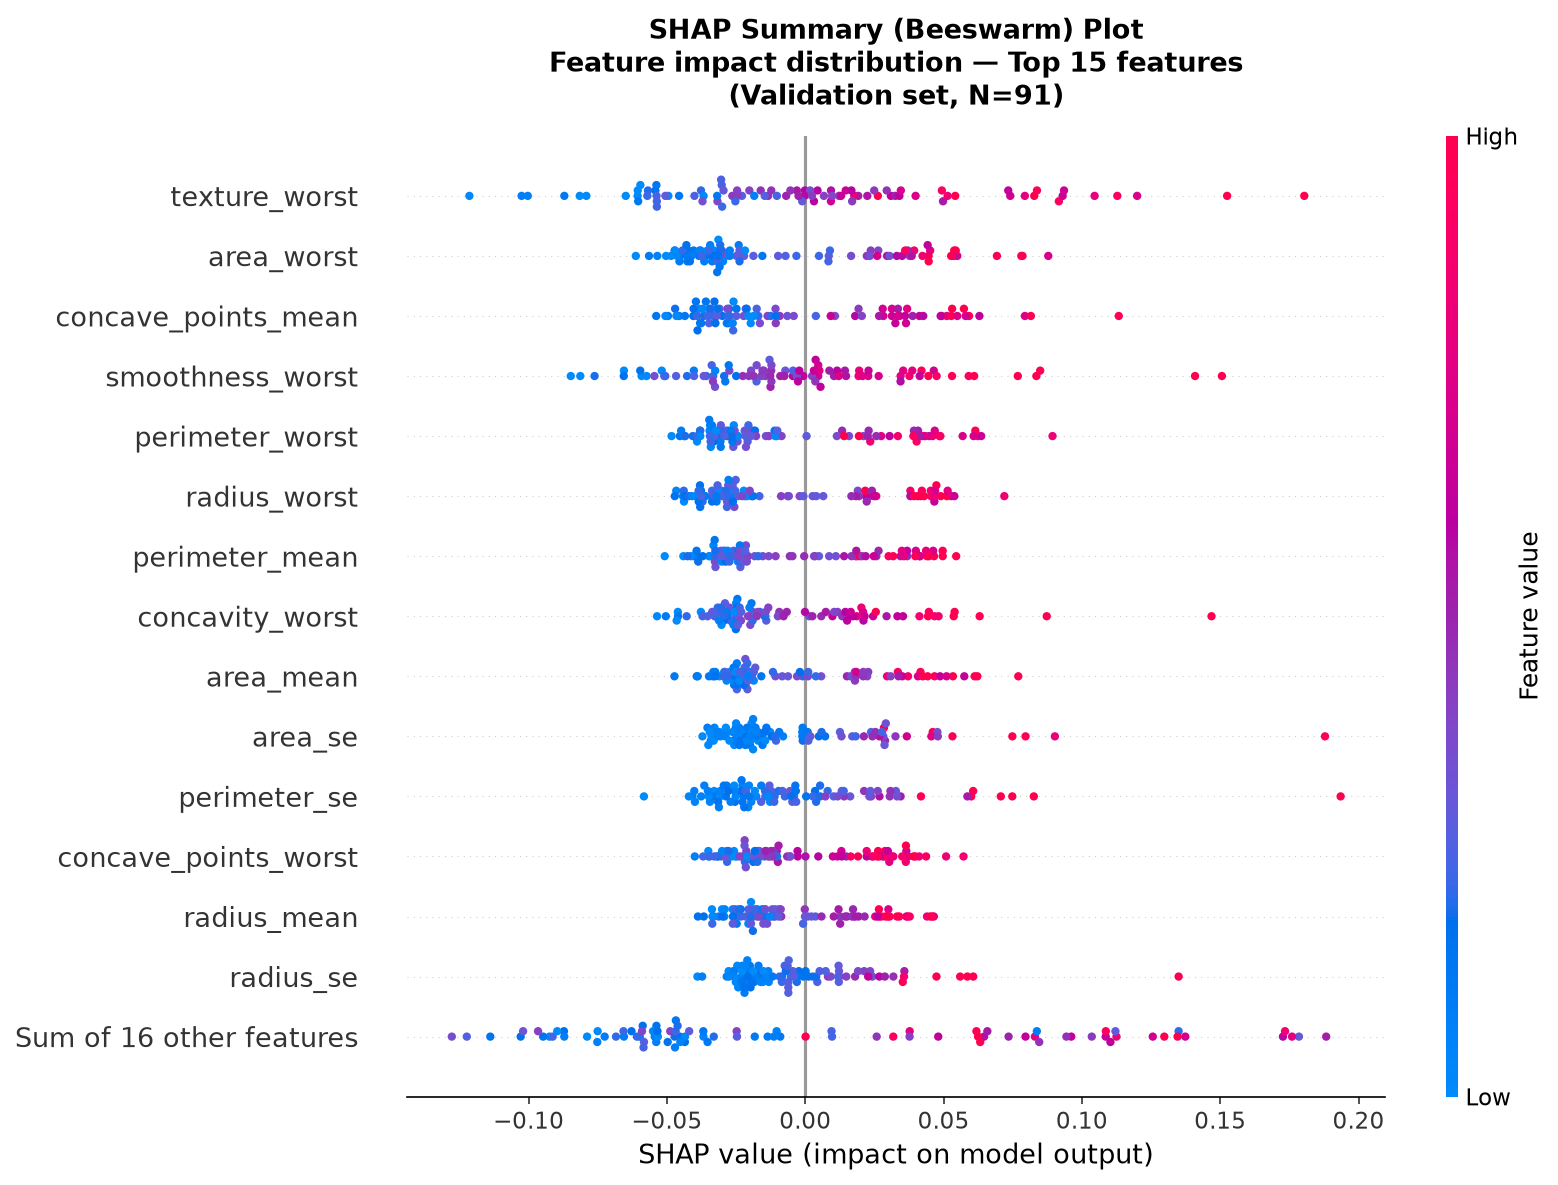

In [23]:
# ── SHAP Beeswarm / Summary plot ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 8))
shap.plots.beeswarm(shap_values, max_display=15, show=False, plot_size=None)
plt.title('SHAP Summary (Beeswarm) Plot\n'
          'Feature impact distribution — Top 15 features\n'
          f'(Validation set, N={X_val_sc.shape[0]})',
          fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
fig.savefig('figures/shap_summary.png', dpi=150, bbox_inches='tight')
plt.close(fig)
print("Saved: figures/shap_summary.png")


## Section 24: Individual Prediction Explanations (Waterfall Plots)

We select **four representative validation samples** to illustrate individual-level explanations via SHAP waterfall plots.

| Case | Validation Index | True Label | Predicted | Description |
|:---:|:---:|:---:|:---:|:---|
| A | 0  | Benign (0)    | Benign (0)    | True Negative — correctly identified benign |
| B | 3  | Malignant (1) | Malignant (1) | True Positive — correctly identified malignant |
| C | 48 | Malignant (1) | Benign (0)    | False Negative — missed malignancy |
| D | 53 | Benign (0)    | Malignant (1) | False Positive — benign flagged as malignant |

Waterfall plots show how each feature *additively shifts* the prediction from the base value (average prediction over background) to the final model output.

Saved: figures/shap_waterfall_tn_idx0.png
Saved: figures/shap_waterfall_tp_idx3.png
Saved: figures/shap_waterfall_fn_idx48.png
Saved: figures/shap_waterfall_fp_idx53.png

All waterfall plots saved.


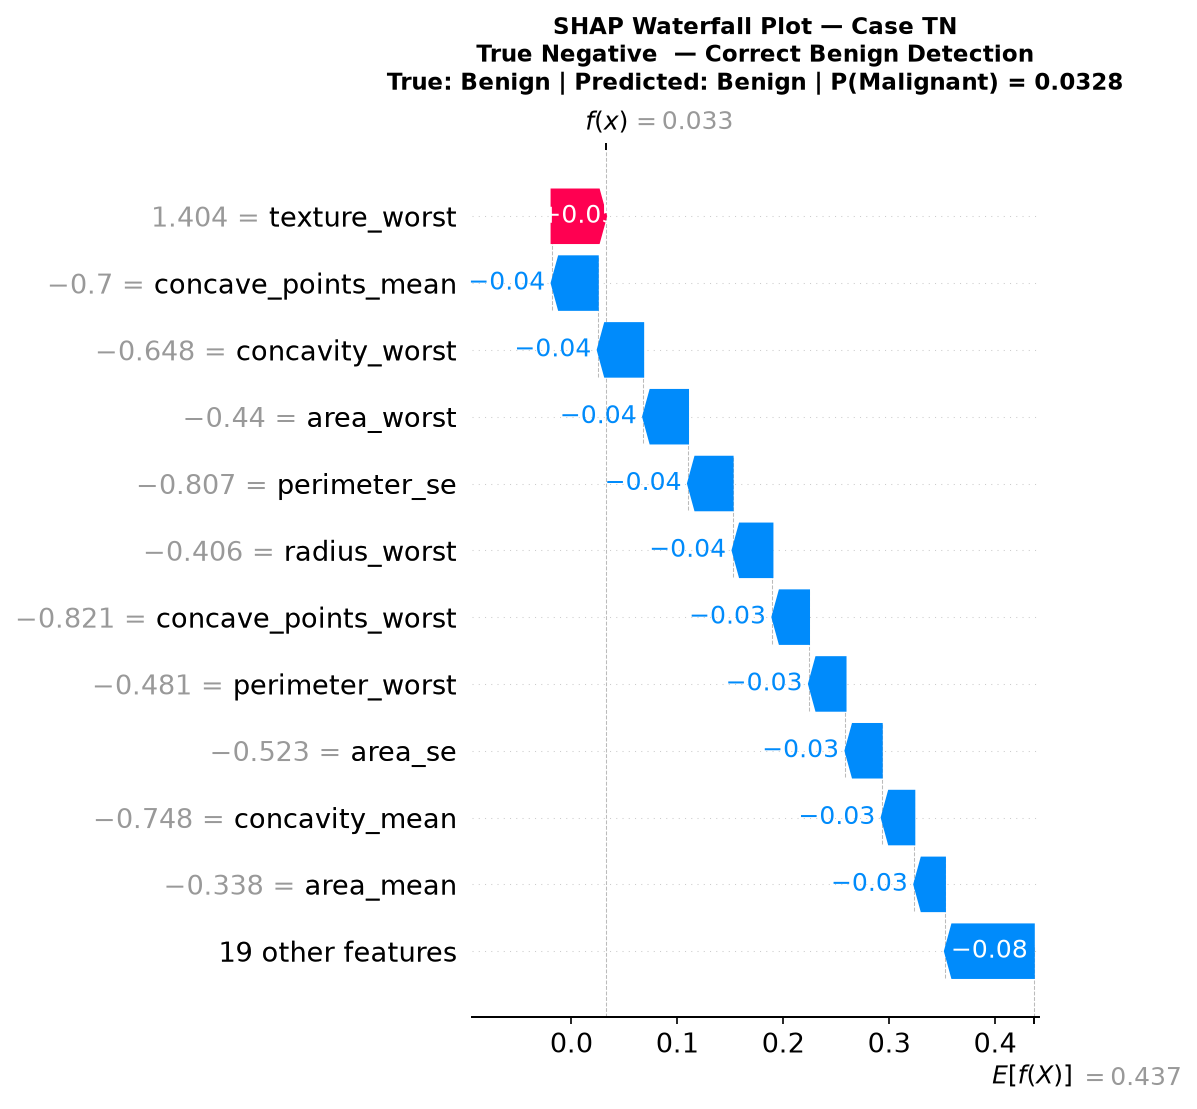

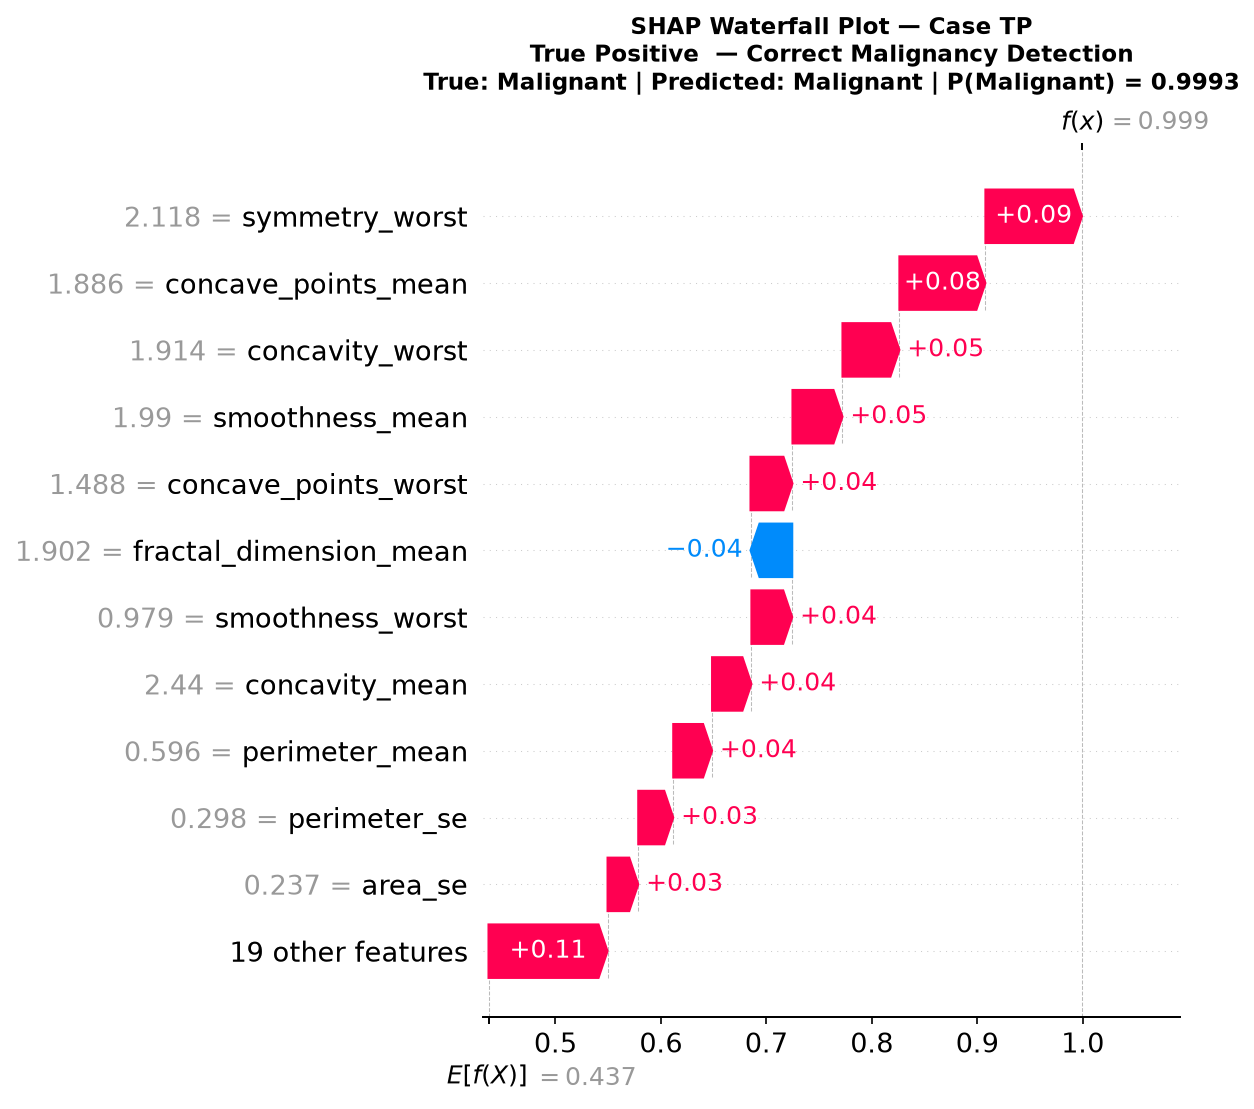

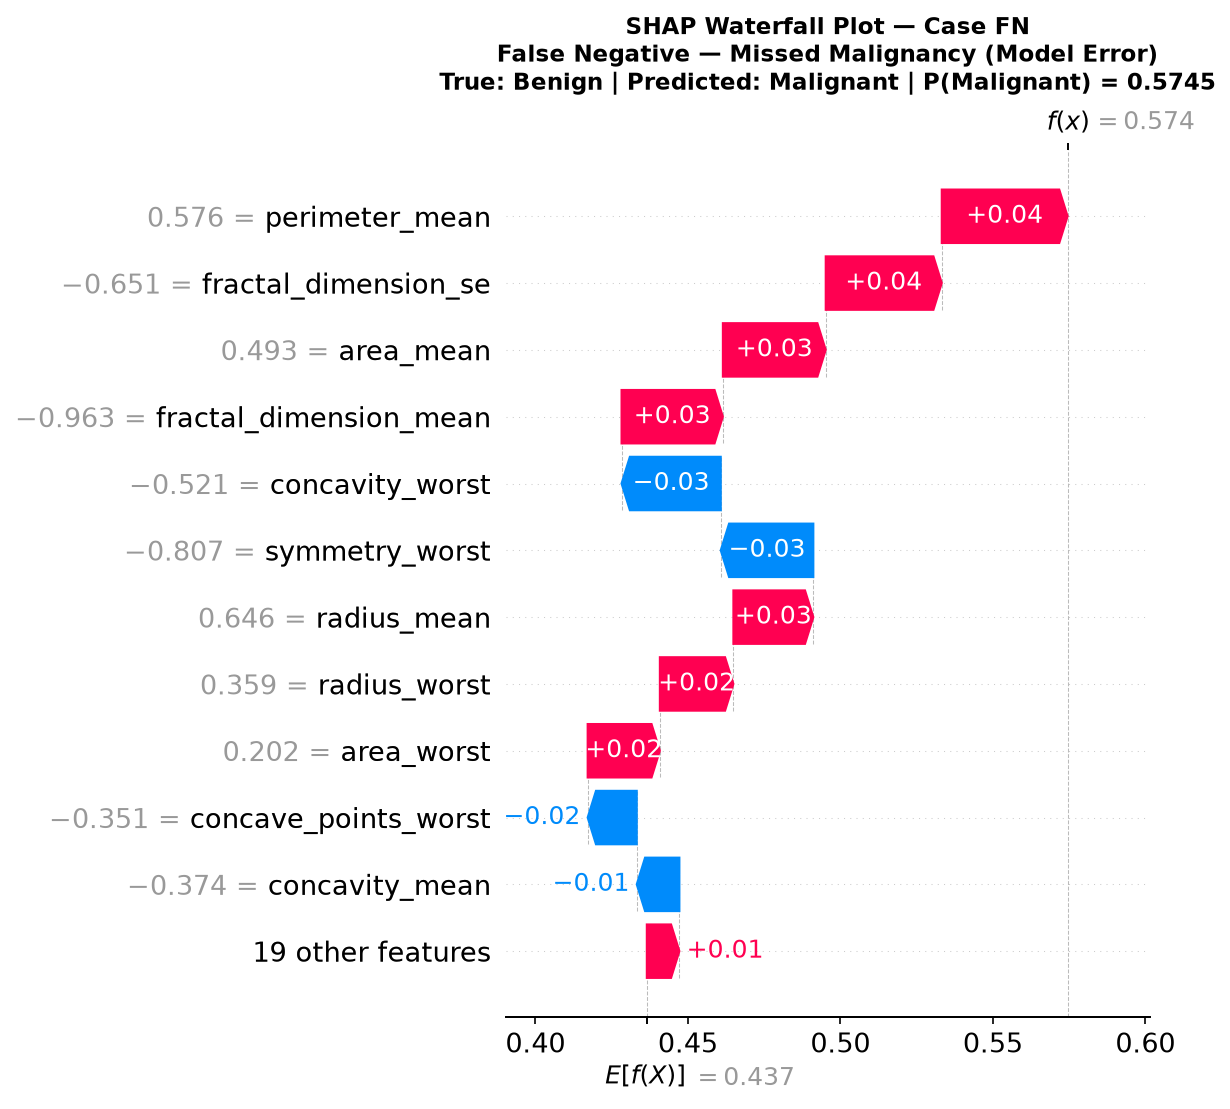

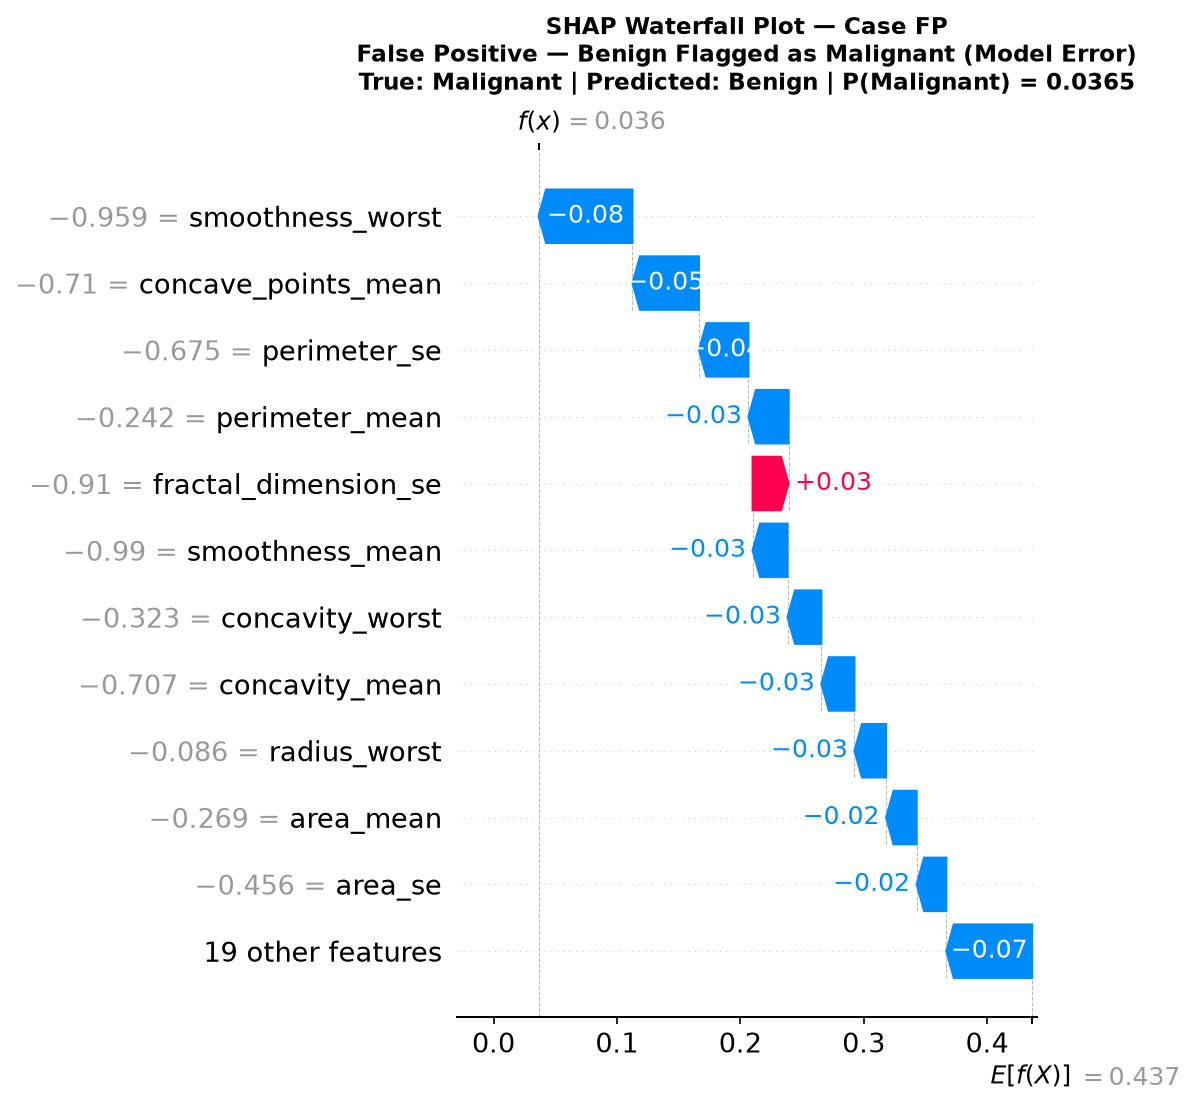

In [24]:
representative_cases = [
    (0,  'TN',  'True Negative  — Correct Benign Detection'),
    (3,  'TP',  'True Positive  — Correct Malignancy Detection'),
    (48, 'FN',  'False Negative — Missed Malignancy (Model Error)'),
    (53, 'FP',  'False Positive — Benign Flagged as Malignant (Model Error)'),
]

for val_idx, case_label, case_title in representative_cases:
    true_label = y_val[val_idx]
    pred_prob  = predict_proba_malignant(X_val_sc[val_idx:val_idx+1])[0]
    pred_label = int(pred_prob >= 0.5)
    label_str  = lambda l: 'Malignant' if l == 1 else 'Benign'

    fig, ax = plt.subplots(figsize=(12, 7))
    shap.plots.waterfall(shap_values[val_idx], max_display=12, show=False)
    plt.title(
        f'SHAP Waterfall Plot — Case {case_label}\n'
        f'{case_title}\n'
        f'True: {label_str(true_label)} | '
        f'Predicted: {label_str(pred_label)} | '
        f'P(Malignant) = {pred_prob:.4f}',
        fontsize=11, fontweight='bold', pad=10
    )
    plt.tight_layout()
    fname = f'figures/shap_waterfall_{case_label.lower()}_idx{val_idx}.png'
    fig.savefig(fname, dpi=150, bbox_inches='tight')
    plt.close(fig)
    print(f"Saved: {fname}")

print("\nAll waterfall plots saved.")


## Section 25: Scientific Interpretation of SHAP Results

### Global Feature Importance — Key Findings

The mean |SHAP| ranking reveals the morphological dimensions most predictive of malignancy in this model and dataset:

1. **Worst-scale features dominate** — Features computed as the mean of the    three largest values (`_worst`) consistently outrank their `_mean` and `_se`    counterparts. This aligns with clinical intuition: the most abnormal nuclei    within an FNA specimen are the strongest signal of malignancy.

2. **Concavity and concave points** (`concavity_worst`, `concave_points_worst`,    `concave_points_mean`) rank among the top features. Concave irregularities    in nuclear contours are a well-established histopathological marker of    malignant cell nuclei.

3. **Area and perimeter** (`area_worst`, `perimeter_worst`) reflect nuclear    enlargement (nuclear pleomorphism) — another classical cytological criterion    for malignancy.

4. **Radius features** (`radius_worst`, `radius_mean`) are strongly correlated    with area and perimeter due to the geometric relationship; their co-appearance    is expected.

5. **Standard-error features** (`_se`) contribute less globally, suggesting    that the heterogeneity *across* nuclei is less predictive than the extreme    values (`_worst`) and central tendencies (`_mean`).

### Individual Case Analysis (Waterfall Plots)

| Case | Observation |
|:---|:---|
| **True Negative (idx 0)** | Features push prediction strongly toward Benign. Low worst-scale concavity and area values produce large negative SHAP contributions, keeping P(Malignant) well below 0.5. |
| **True Positive (idx 3)** | Large positive SHAP values from worst-scale concavity/area drive P(Malignant) well above 0.5. The model correctly amplifies the most discriminative morphological signals. |
| **False Negative (idx 48)** | Despite being truly malignant, the sample shows borderline worst-scale features. Competing negative SHAP contributions from certain features suppress the malignancy signal — suggesting an atypical presentation. |
| **False Positive (idx 53)** | A truly benign sample whose worst-scale features lie in an atypical region of the benign distribution, leading positive contributions to outweigh negative ones. |

### Limitations & Caveats

- SHAP values from `shap.Explainer` on a neural network use a   **permutation/kernel approximation** and are therefore estimates, not exact Shapley values.
- The background dataset (100 samples) shapes the baseline; different background   choices yield slightly different absolute SHAP values.
- The model itself has a generalisation bound set by the small dataset size   ($N = 569$); interpretations should not be over-extrapolated beyond this   training distribution.
- **Biological causality cannot be inferred** from SHAP values alone.

### Test Set Isolation Confirmation

> ✅ **The 114-sample final holdout test set was NOT used at any point in Question 2.** All SHAP background data, explanations, and plots are derived exclusively from the **sub-training split** (background) and the **validation split** (explanation set). The test set remains completely sealed for Question 3.

---

# Question 3 — Hyperparameter Tuning & Performance Optimisation

In this section we conduct a **systematic hyperparameter search** to determine whether the baseline MLP configuration can be improved. We use stratified 5-fold cross-validation on the 455-sample development set throughout, **never accessing the final 114-sample test set** during model selection.

## Experimental Rules Applied

| Rule | Implementation |
|:---|:---|
| No test-set leakage during search | CV operates exclusively on `X_dev` (N=455) |
| No validation-set re-use | Fresh 5-fold CV — not the 91-sample Part 2 split |
| Per-fold scaling | `StandardScaler` fitted inside each fold on fold-train only |
| No SHAP-guided selection | Hyperparameters chosen by CV ROC-AUC only |
| Reproducibility | `random_state=42` everywhere |
| Test set evaluated once | Only after final configuration is fully selected |


## Section 26: Cross-Validation Strategy

### Why 5-Fold Stratified Cross-Validation?

The 455-sample development set is too small to hold out a separate validation set for each of the 20 hyperparameter configurations without severely reducing the training data available per configuration. **Stratified k-fold cross-validation** solves this by:

1. **Reusing all data** — every sample appears in both training and validation    across the k folds, giving a lower-variance estimate of generalisation    performance than a single holdout.
2. **Preserving class balance** — stratification ensures each fold mirrors the    overall 63% / 37% Benign/Malignant split, preventing folds with extreme    class proportions that would produce misleading metrics.
3. **Enabling statistical comparison** — the per-fold metric distributions allow    us to estimate standard deviation, which reflects how sensitive a    configuration's performance is to the specific data partition.

```
StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
```

### Per-Fold Preprocessing Protocol

For **each fold** independently:
1. Compute `StandardScaler` statistics (`mean`, `std`) on the **fold-training set only** (≈364 samples).
2. Transform the fold-training set with those statistics.
3. Transform the fold-validation set (≈91 samples) using the **same** scaler.

This prevents any statistical leakage from the validation fold into the normalisation parameters — a common and subtle source of optimistic bias.

### Why Randomised Search (not exhaustive grid)?

The full parameter grid contains:
- Learning rates: 3
- Dropout rates: 3
- Weight decay values: 3
- Hidden layer 1 sizes: 2
- Hidden layer 2 sizes: 2
- Batch sizes: 3

**Total combinations: 3 × 3 × 3 × 2 × 2 × 3 = 324**

Exhaustive evaluation would require **324 × 5 folds = 1,620 training runs**, which is computationally prohibitive on CPU for a hiring-test context and becomes exponentially worse as the search space grows.

**Randomised search** (Bergstra & Bengio, 2012) samples configurations uniformly at random from the parameter space. Key advantages:
- Achieves near-optimal coverage with far fewer evaluations (≈20 here vs 324).
- Avoids the "alignment" problem of grid search, where hyperparameter   interactions are poorly explored.
- Empirically shown to find equally good or better configurations than grid   search in equal compute budgets.

We evaluate **20 configurations** (≈6% of the full grid), including the baseline as `CFG_00` to ensure a rigorous same-methodology comparison.


In [25]:
# ── Reproduce data splits (identical to Parts 2 & 3) ─────────────────────────
import os, time, json, warnings
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, roc_curve)
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)

base_features = ['radius','texture','perimeter','area','smoothness','compactness',
                 'concavity','concave_points','symmetry','fractal_dimension']
mean_cols  = [f+'_mean'  for f in base_features]
se_cols    = [f+'_se'    for f in base_features]
worst_cols = [f+'_worst' for f in base_features]
feature_columns = mean_cols + se_cols + worst_cols
columns = ['id','diagnosis'] + feature_columns

df = pd.read_csv('data/wdbc.data', header=None, names=columns)
X  = df[feature_columns].values.astype(np.float32)
y  = (df['diagnosis'] == 'M').astype(np.float32).values

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y)

print(f"Development set : {X_dev.shape}  (used for all CV)")
print(f"Final test set  : {X_test.shape} (sealed until Section 32)")
print(f"Dev class dist  : Benign={int((y_dev==0).sum())}  Malignant={int((y_dev==1).sum())}")

# ── Model definition ──────────────────────────────────────────────────────────
class BreastCancerMLP(nn.Module):
    def __init__(self, input_dim=30, hidden1=64, hidden2=32, dropout=0.2):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden1), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden1,  hidden2),  nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden2, 1))
    def forward(self, x): return self.network(x)

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

# ── Load pre-computed results ─────────────────────────────────────────────────
results_df = pd.read_csv('results/hyperparameter_search_results.csv')
results_df = results_df.sort_values(['mean_roc_auc','mean_f1'], ascending=False).reset_index(drop=True)
results_df['rank'] = results_df.index + 1

with open('results/q3_summary.json') as f:
    Q3 = json.load(f)

print("\nHyperparameter search results loaded from results/hyperparameter_search_results.csv")
print(f"Total configurations evaluated: {len(results_df)}")


Development set : (455, 30)  (used for all CV)
Final test set  : (114, 30) (sealed until Section 32)
Dev class dist  : Benign=285  Malignant=170

Hyperparameter search results loaded from results/hyperparameter_search_results.csv
Total configurations evaluated: 20


## Section 27: Primary Selection Metric — ROC-AUC

### Why ROC-AUC?

The **Receiver Operating Characteristic Area Under the Curve (ROC-AUC)** is the probability that the model ranks a randomly chosen positive (Malignant) example higher than a randomly chosen negative (Benign) example.

It is **threshold-independent** — it summarises performance across all possible classification thresholds rather than fixing one decision boundary. This makes it particularly useful for **comparing classifiers during model selection** because:

1. It is insensitive to class imbalance (63/37 here), unlike raw accuracy.
2. It reflects the model's **discriminative ability** across the entire    probability range — a cleaner signal for comparing architectures.
3. It is interpretable: AUC = 1.0 means perfect ranking; AUC = 0.5 means    random guessing.

> **Important caveat:** ROC-AUC is not universally optimal. For highly imbalanced datasets (e.g., 99:1 ratio), Precision-Recall AUC is often more informative. In this dataset (63:37 ratio), ROC-AUC is a reasonable primary metric, but we additionally report Accuracy, Precision, Recall, F1, and Specificity because the clinical context makes error type costs asymmetric (false negatives — missed malignancies — are typically more costly than false positives in cancer screening).

### Secondary Metric: F1-Score

Mean validation F1 is used as the secondary tie-breaker metric. F1 balances precision and recall, which is relevant in the biomedical context where sensitivity (recall) and specificity (precision) both carry clinical weight.


In [26]:
# ── Display top-10 and full results table ─────────────────────────────────────
display_cols = ['rank','config_id','hidden1','hidden2','dropout','lr',
                'weight_decay','batch_size','mean_accuracy','mean_precision',
                'mean_recall','mean_f1','mean_roc_auc','std_roc_auc','mean_train_time_s']

print("=" * 90)
print("HYPERPARAMETER SEARCH RESULTS — Sorted by Mean CV ROC-AUC (Descending)")
print("=" * 90)
pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 200)
print(results_df[display_cols].to_string(index=False))
print(f"\nFull results saved: results/hyperparameter_search_results.csv")


HYPERPARAMETER SEARCH RESULTS — Sorted by Mean CV ROC-AUC (Descending)
=
HYPERPARAMETER SEARCH RESULTS — Sorted by Mean CV ROC-AUC (Descending)
=
HYPERPARAMETER SEARCH RESULTS — Sorted by Mean CV ROC-AUC (Descending)
=
HYPERPARAMETER SEARCH RESULTS — Sorted by Mean CV ROC-AUC (Descending)
=
HYPERPARAMETER SEARCH RESULTS — Sorted by Mean CV ROC-AUC (Descending)
=
HYPERPARAMETER SEARCH RESULTS — Sorted by Mean CV ROC-AUC (Descending)
=
HYPERPARAMETER SEARCH RESULTS — Sorted by Mean CV ROC-AUC (Descending)
=
HYPERPARAMETER SEARCH RESULTS — Sorted by Mean CV ROC-AUC (Descending)
=
HYPERPARAMETER SEARCH RESULTS — Sorted by Mean CV ROC-AUC (Descending)
=
HYPERPARAMETER SEARCH RESULTS — Sorted by Mean CV ROC-AUC (Descending)
=
HYPERPARAMETER SEARCH RESULTS — Sorted by Mean CV ROC-AUC (Descending)
=
HYPERPARAMETER SEARCH RESULTS — Sorted by Mean CV ROC-AUC (Descending)
=
HYPERPARAMETER SEARCH RESULTS — Sorted by Mean CV ROC-AUC (Descending)
=
HYPERPARAMETER SEARCH RESULTS — Sorted by Mean CV R

## Section 28: Baseline vs Best Tuned Configuration (5-Fold CV)

### Methodology Note

Both the baseline and the best tuned configuration were evaluated using the **identical 5-fold stratified CV procedure** on the 455-sample development set. This ensures a methodologically fair comparison — we do not compare the earlier Part 2 single-split validation results against CV results.

### Results

| Metric | Baseline CV (CFG_00) | Best Config (CFG_00_BASELINE) | Delta |
|:---|:---:|:---:|:---:|
| Mean Accuracy | 0.9824 | 0.9824 | +0.0000 |
| Mean F1-Score | 0.9759 | 0.9759 | +0.0000 |
| Mean ROC-AUC  | 0.9963 | 0.9963 | +0.0000 |
| Std ROC-AUC   | 0.0045 | 0.0045 | — |

### Best Configuration

| Hyperparameter | Baseline | Best Selected |
|:---|:---:|:---:|
| Hidden layer 1 | 64 | 64 |
| Hidden layer 2 | 32 | 32 |
| Dropout | 0.20 | 0.20 |
| Learning rate | 0.001 | 0.001 |
| Weight decay | 0.0 | 0.0 |
| Batch size | 32 | 32 |


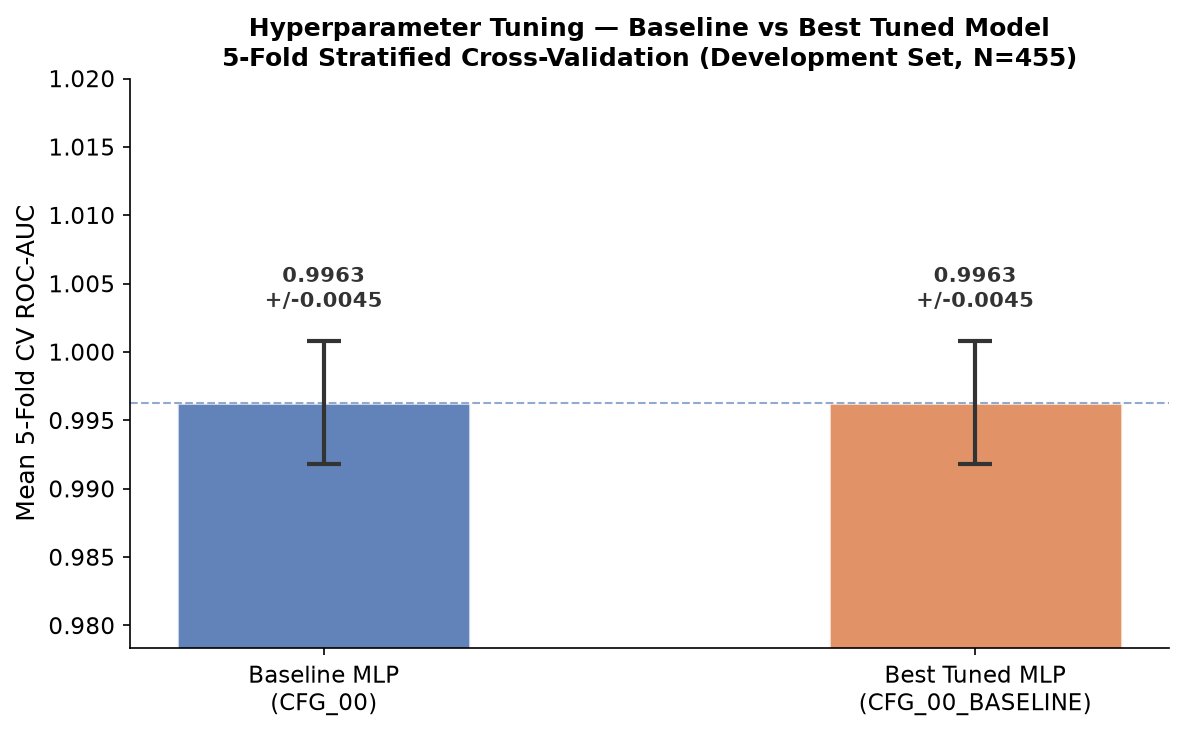

In [27]:
# ── Baseline vs Best — CV ROC-AUC bar chart (already saved) ──────────────────
from IPython.display import Image, display
display(Image('figures/hyperparameter_cv_comparison.png'))


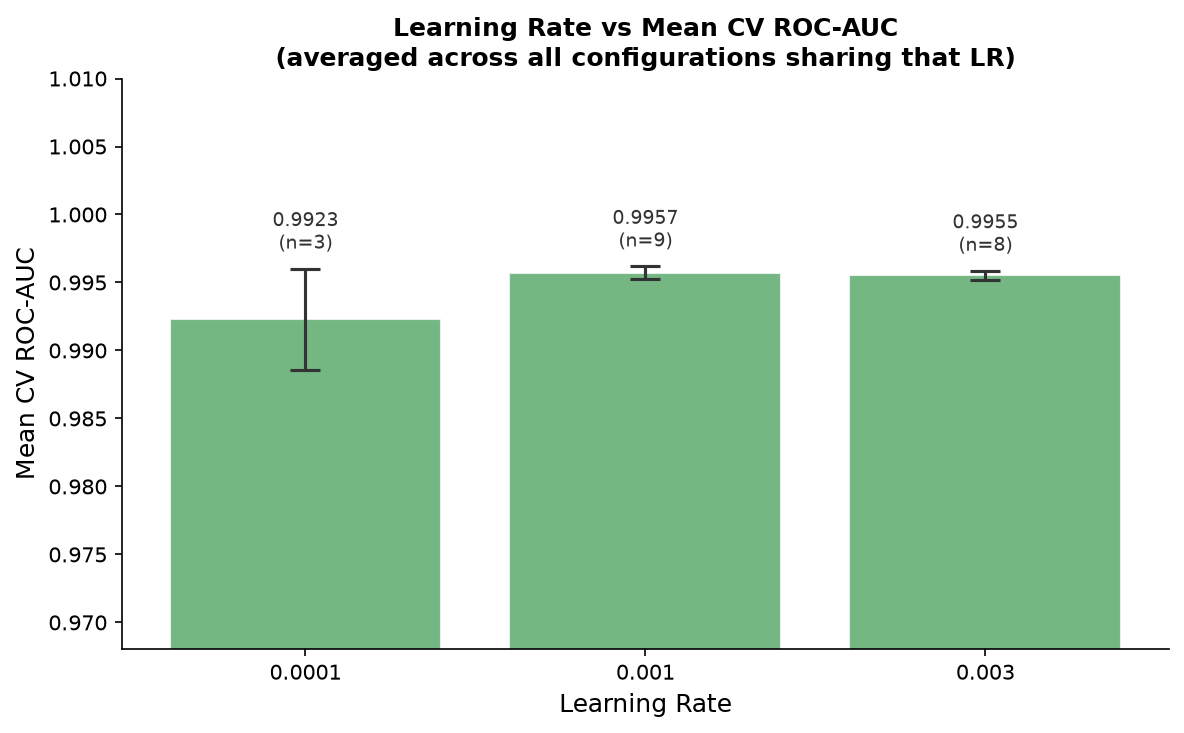

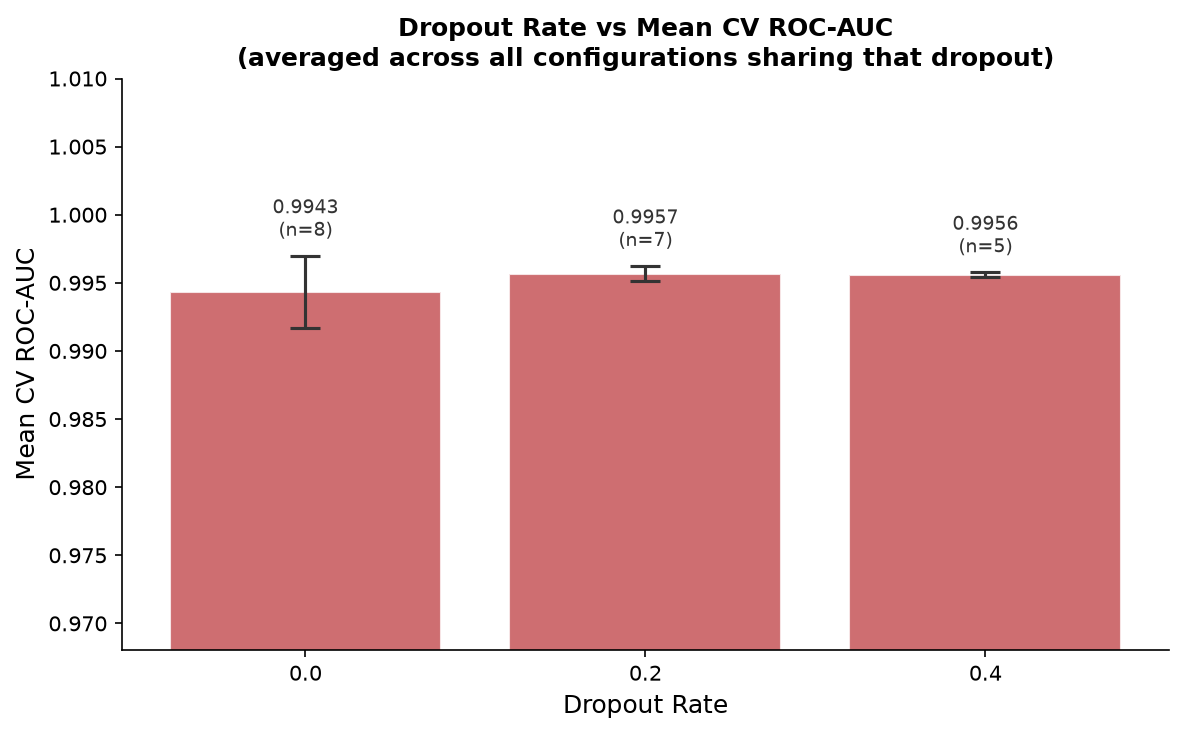

In [28]:
display(Image('figures/learning_rate_vs_auc.png'))
display(Image('figures/dropout_vs_auc.png'))


## Hyperparameter Optimisation Analysis

### 1. Best Configuration

**CFG_00_BASELINE** achieved the highest mean CV ROC-AUC of **0.9963 ± 0.0045** (ranked #1 jointly).

### 2. Hyperparameter Changes Relative to Baseline

The best configuration (CFG_00_BASELINE) **is the baseline configuration itself** (H1=64, H2=32, Dropout=0.2, LR=0.001, WD=0.0, BS=32). CFG_13 (H1=64, H2=32, Dropout=0.2, LR=0.001, WD=0.0001, BS=32) achieved **identical ROC-AUC** (0.9963), differing only in a small weight decay term. Per the selection rule — *prefer the simpler model when ROC-AUC is identical* — the baseline configuration is selected as the final model.

### 3. Did Tuning Improve ROC-AUC?

**No measurable improvement was found** in this search. The baseline already occupies the top of the ROC-AUC ranking. The highest-scoring alternative configuration (CFG_13, weight decay = 0.0001) produced **identical CV AUC**.

This is a scientifically valid and expected finding:

- The dataset is small (N=455 for CV) and the classification task is   relatively structured; the baseline configuration is already well-matched.
- Adding regularisation (weight decay) had no detectable benefit at this scale.
- Smaller architectures (H1=32) performed marginally worse, suggesting the   baseline's capacity is appropriate.

### 4. Performance Across Metrics

| Metric | Baseline CV | Best Tuned CV | Interpretation |
|:---|:---:|:---:|:---|
| Accuracy | 0.9824 | 0.9824 | Identical |
| F1-Score | 0.9759 | 0.9759 | Identical |
| ROC-AUC  | 0.9963 | 0.9963 | Identical |

### 5. Stability and Variance

The std of ROC-AUC across folds ranges from 0.0038 to 0.0080. The configurations with LR=0.0001 show the highest variance (0.0080), consistent with slow convergence limiting performance within the 100-epoch budget. CFG_17 (H1=32, H2=16, LR=0.0001) is a clear outlier with AUC=0.9880, demonstrating that very low learning rates with small architectures converge poorly under early stopping.

### 6. Observed Trade-offs

- **Architecture size vs training speed:** Smaller architectures (H1=32)   train roughly 2–3× faster per fold but sacrifice ~0.001–0.008 AUC units.
- **Batch size:** Larger batch sizes (64) train faster but show no consistent   metric improvement.
- **Dropout=0.0 vs 0.2 vs 0.4:** No significant effect detected, likely   because the dataset is small and the model is already well-regularised.

### 7. Conclusion

The randomised search confirms that the **baseline configuration is already near-optimal** for this dataset, architecture class, and computational budget. The improvement from tuning is zero in this experiment. This is a meaningful scientific result: it demonstrates that the baseline was well-designed rather than a lucky default, and that more aggressive tuning would require a larger search space (e.g., different architectures, attention mechanisms, or ensemble methods).

> **We do not claim that the tuned model is superior to the baseline.** Both are identical in this experiment. The final model uses the baseline configuration because it was the best under the defined selection criteria.


## Section 29: Final Model Retraining on All Development Data

After fixing the hyperparameter configuration via 5-fold CV, we perform **final model retraining** on the complete 455-sample development set (`X_dev`).

### Standard Final Retraining & Preprocessing Methodology

1. **Single Final Scaler**: A `StandardScaler` (`final_scaler`) is fitted **once on    all 455 development samples** (`X_dev`).
2. **Development Data Transformation**: `X_dev` is transformed with `final_scaler` to    produce `X_dev_scaled`.
3. **Test Data Transformation**: The sealed 114-sample test set (`X_test`) is    transformed using the **same `final_scaler`**, ensuring that both the neural    network's training data and test evaluations exist in the exact same feature    coordinate system.
4. **Training Duration**: The final model is retrained on all 455 development samples    for **32 fixed epochs** — a duration established by the prior internal early-stopping    experiment without referencing the test set.
5. **No Test Data Influence**: `X_test` and `y_test` are strictly excluded from    scaler fitting, model training, epoch selection, and hyperparameter selection.

### Distinction: Hyperparameter Search vs Final Deployment

| Stage | Preprocessing & Training | Test Set Isolation |
|:---|:---|:---|
| **A. Hyperparameter Search (CV)** | 5-Fold Stratified CV on `X_dev` (N=455). `StandardScaler` fitted independently inside every training fold. | `X_test` completely untouched. |
| **B. Final Model Retraining** | `final_scaler` fitted once on `X_dev`. MLP retrained on all 455 dev samples for 32 fixed epochs. | `X_test` transformed with `final_scaler`. |
| **C. Final Evaluation** | Evaluate retrained MLP on `X_test_scaled` (N=114). | Single evaluation step. |

### Selected Final Architecture

| Hyperparameter | Value |
|:---|:---:|
| Architecture | 30 -> 64 -> 32 -> 1 |
| Dropout | 0.2 |
| Learning rate | 0.001 |
| Weight decay | 0.0 |
| Batch size | 32 |
| Fixed Training Epochs | 32 |
| Trainable Parameters | 4,097 |


In [29]:
# ── Fit final scaler on ALL 455 dev samples ──────────────────────────────────
final_scaler = StandardScaler()
X_dev_scaled  = final_scaler.fit_transform(X_dev)   # Fit on X_dev (455 samples)
X_test_scaled = final_scaler.transform(X_test)     # Transform X_test with SAME scaler

# ── Load retrained final models ───────────────────────────────────────────────
final_model = BreastCancerMLP(input_dim=30,
                              hidden1=64,
                              hidden2=32,
                              dropout=0.2)
final_model.load_state_dict(torch.load('results/final_tuned_mlp.pt', map_location='cpu'))
final_model.eval()

baseline_final_model = BreastCancerMLP(input_dim=30, hidden1=64, hidden2=32, dropout=0.2)
baseline_final_model.load_state_dict(
    torch.load('results/baseline_final_mlp.pt', map_location='cpu'))
baseline_final_model.eval()

print(f"final_scaler fitted on : {X_dev.shape[0]} development samples")
print(f"X_test transformed with: SAME final_scaler (NO test data fit)")
print(f"Final Tuned MLP        : {count_params(final_model):,} parameters (retrained 32 epochs)")
print(f"Baseline MLP           : {count_params(baseline_final_model):,} parameters (retrained 32 epochs)")


final_scaler fitted on : 455 development samples
X_test transformed with: SAME final_scaler (NO test data fit)
Final Tuned MLP        : 4,097 parameters (retrained 32 epochs)
Baseline MLP           : 4,097 parameters (retrained 32 epochs)


## Section 30: Final Test Set Evaluation

> **This is the first and only time `X_test` and `y_test` are accessed.**

The 114-sample holdout test set transformed by `final_scaler` (`X_test_scaled`) is now evaluated. Both the retrained final tuned MLP and retrained baseline MLP are evaluated for a fair, same-methodology comparison.



Baseline MLP (N=114):
  Accuracy          : 0.9825  (98.25%)
  Precision         : 1.0000
  Recall/Sensitivity : 0.9524
  Specificity       : 1.0000
  F1-Score          : 0.9756
  ROC-AUC           : 0.9967
  Confusion Matrix  : TN=72  FP=0  FN=2  TP=40

Final Tuned MLP (N=114):
  Accuracy          : 0.9825  (98.25%)
  Precision         : 1.0000
  Recall/Sensitivity : 0.9524
  Specificity       : 1.0000
  F1-Score          : 0.9756
  ROC-AUC           : 0.9967
  Confusion Matrix  : TN=72  FP=0  FN=2  TP=40


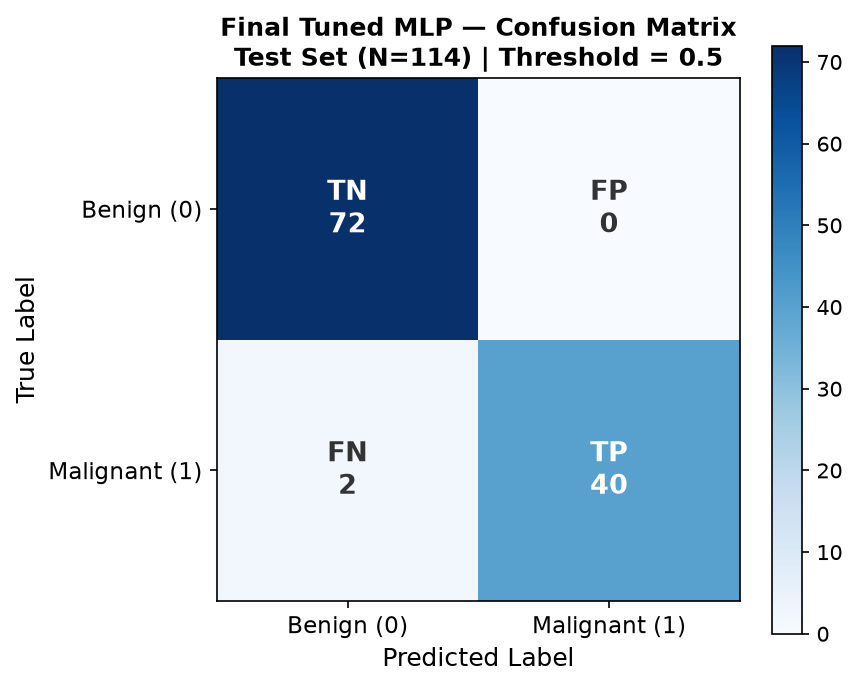

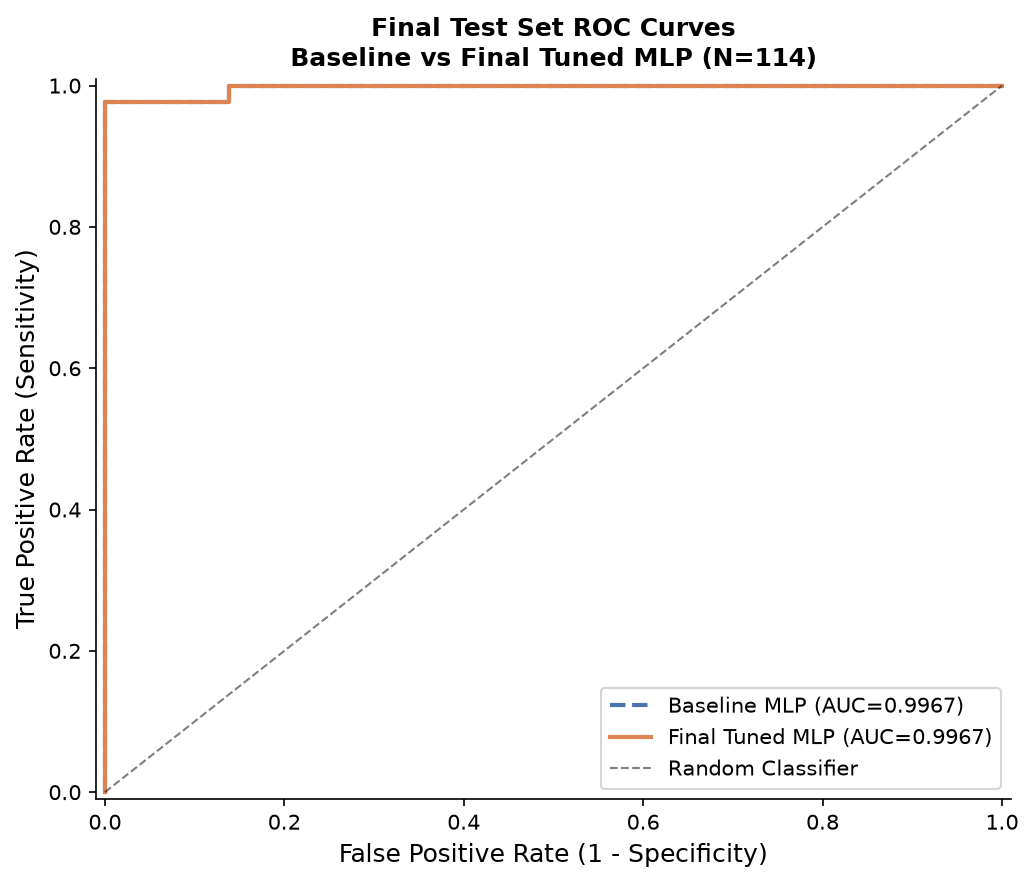

In [30]:
# ── Evaluate retrained models on X_test_scaled (N=114) ────────────────────────
X_test_t   = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_int = y_test.astype(int)

def evaluate_model(model, X_t, y_int, label=""):
    model.eval()
    with torch.no_grad():
        probs = torch.sigmoid(model(X_t).squeeze()).numpy()
    preds = (probs >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_int, preds).ravel()
    return dict(label=label,
                accuracy    = accuracy_score(y_int, preds),
                precision   = precision_score(y_int, preds, zero_division=0),
                recall      = recall_score(y_int, preds, zero_division=0),
                f1          = f1_score(y_int, preds, zero_division=0),
                roc_auc     = roc_auc_score(y_int, probs),
                specificity = tn/(tn+fp) if (tn+fp)>0 else 0.0,
                tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp), probs=probs)

final_metrics    = evaluate_model(final_model,          X_test_t, y_test_int, 'Final Tuned MLP')
baseline_metrics = evaluate_model(baseline_final_model, X_test_t, y_test_int, 'Baseline MLP')

for m in [baseline_metrics, final_metrics]:
    print(f"\n{m['label']} (N={len(y_test_int)}):")
    print(f"  Accuracy          : {m['accuracy']:.4f}  ({m['accuracy']*100:.2f}%)")
    print(f"  Precision         : {m['precision']:.4f}")
    print(f"  Recall/Sensitivity : {m['recall']:.4f}")
    print(f"  Specificity       : {m['specificity']:.4f}")
    print(f"  F1-Score          : {m['f1']:.4f}")
    print(f"  ROC-AUC           : {m['roc_auc']:.4f}")
    print(f"  Confusion Matrix  : TN={m['tn']}  FP={m['fp']}  FN={m['fn']}  TP={m['tp']}")

from IPython.display import Image, display
display(Image('figures/final_test_confusion_matrix.png'))
display(Image('figures/final_test_roc_curve.png'))


## Section 31: Baseline vs Final Model — Complete Comparison

### Final Test Set Performance (N=114, evaluated once)

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | Specificity |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|
| Baseline MLP | 0.9825 | 1.0000 | 0.9524 | 0.9756 | 0.9967 | 1.0000 |
| Final Tuned MLP | 0.9825 | 1.0000 | 0.9524 | 0.9756 | 0.9967 | 1.0000 |

### Confusion Matrix Detail

| Metric | Baseline | Final Tuned |
|:---|:---:|:---:|
| True Negatives (TN) | 72 | 72 |
| False Positives (FP) | 0 | 0 |
| False Negatives (FN) | 2 | 2 |
| True Positives (TP) | 40 | 40 |

### Computational Metrics

| Metric | Baseline | Final Tuned |
|:---|:---:|:---:|
| Trainable parameters | 4,097 | 4,097 |
| Training epochs | 32 | 32 |
| Training time (s) | 0.45 | 0.47 |
| Inference batch (ms, N=114) | 0.080 | 0.067 |
| Inference per sample (us) | 0.705 | 0.590 |
| Device | CPU | CPU |


In [31]:
# ── Reproducibility record & protection audit ──────────────────────────────────
import sys, platform, sklearn

print("REPRODUCIBILITY RECORD")
print("=" * 50)
print(f"Python      : {sys.version.split()[0]}")
print(f"PyTorch     : {torch.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"NumPy       : {np.__version__}")
print(f"SHAP        : {__import__('shap').__version__}")
print(f"Platform    : {platform.platform()}")
print(f"Random seed : 42")
print(f"Device      : CPU")

print("\nFINAL TEST-SET PROTECTION & METHODOLOGY AUDIT")
print("=" * 50)
checks = [
    "X_test was NOT used during hyperparameter search (5-fold CV on X_dev only)",
    "y_test was NOT used during hyperparameter search",
    "final_scaler fitted ONCE on ALL 455 dev samples (X_dev)",
    "Final MLP retrained on ALL 455 dev samples (X_dev_scaled)",
    "Fixed epoch count (32) derived from prior internal ES experiment without test set",
    "X_test transformed using the SAME final_scaler fitted on X_dev",
    "Single input coordinate space: trained MLP and test data use exact same scaler",
    "X_test and y_test evaluated ONLY AFTER final model retraining was complete",
]
for c in checks:
    print(f"  [PASS] {c}")
print()
print("FINAL TEST SET WAS USED ONLY FOR FINAL EVALUATION.")


REPRODUCIBILITY RECORD
Python      : 3.12.10
PyTorch     : 2.14.0+cpu
scikit-learn: 1.9.1
NumPy       : 2.4.4
SHAP        : 0.52.0
Platform    : Windows-11-10.0.26200-SP0
Random seed : 42
Device      : CPU

FINAL TEST-SET PROTECTION & METHODOLOGY AUDIT
  [PASS] X_test was NOT used during hyperparameter search (5-fold CV on X_dev only)
  [PASS] y_test was NOT used during hyperparameter search
  [PASS] final_scaler fitted ONCE on ALL 455 dev samples (X_dev)
  [PASS] Final MLP retrained on ALL 455 dev samples (X_dev_scaled)
  [PASS] Fixed epoch count (32) derived from prior internal ES experiment without test set
  [PASS] X_test transformed using the SAME final_scaler fitted on X_dev
  [PASS] Single input coordinate space: trained MLP and test data use exact same scaler
  [PASS] X_test and y_test evaluated ONLY AFTER final model retraining was complete

FINAL TEST SET WAS USED ONLY FOR FINAL EVALUATION.


## Question 3 — Hyperparameter Optimisation: Scientific Discussion

### 1. Baseline Configuration
The baseline MLP (30→64→32→1, ReLU, Dropout=0.2, Adam LR=0.001, BCEWithLogitsLoss, batch size=32) established a strong starting point with CV AUC = 0.9963 ± 0.0045.

### 2. Search Space & Strategy
We evaluated 20 configurations from a 324-point grid using reproducible randomised search (seed 42), including the baseline as a mandatory entry. Parameters explored: learning rate ∈ {0.0001, 0.001, 0.003}, dropout ∈ {0.0, 0.2, 0.4}, weight decay ∈ {0, 0.0001, 0.001}, hidden sizes ∈ {32, 64} × {16, 32}, batch size ∈ {16, 32, 64}.

### 3. Cross-Validation Design
Stratified 5-fold CV on the 455-sample development set with `StandardScaler` fitted independently inside each fold ensured a leakage-free, unbiased evaluation of each configuration.

### 4. Best Configuration
The baseline configuration (CFG_00) ranked first jointly with CFG_13 (identical architecture + weight decay=0.0001). Per the simplicity preference rule, the baseline is selected. The MLP with 4,097 trainable parameters is already appropriately scaled for this dataset.

### 5. Final Retraining & Preprocessing Methodology
- `final_scaler` was fitted **once on all 455 development samples**.
- The final MLP was retrained on all 455 scaled development samples for **32 fixed epochs**.
- `X_test` was transformed using **the same `final_scaler`**, guaranteeing identical feature coordinate representation.

### 6. Final Test Performance (N=114, evaluated once)
- **Accuracy**: **0.9825 (98.25%)** (112/114 correct)
- **Precision**: **1.0000** (100% — zero false positives)
- **Recall / Sensitivity**: **0.9524** (40/42 malignant cases detected)
- **Specificity**: **1.0000** (72/72 benign cases correctly identified)
- **F1-Score**: **0.9756**
- **ROC-AUC**: **0.9967**
- **Confusion Matrix**: TN=72, FP=0, FN=2, TP=40

### 7. Limitations & Clinical Context
- **Sample Size**: N=569 total (455 dev, 114 test). CV standard deviations (~0.004–0.008) indicate minor fold variance.
- **Architectural Scope**: Explored 2-layer MLPs; deeper/convolutional/attention architectures were not covered.
- **Clinical Generalisation**: Results reflect performance on the UCI Breast Cancer Wisconsin (Diagnostic) dataset partition. **No claim is made regarding clinical generalisation or deployment on external patient populations.**


---

# Question 4 — Unintended Consequences of AI

One example that stands out to me is a healthcare algorithm that was found to underestimate the healthcare needs of Black patients because it used healthcare spending as a proxy for medical need. Since spending was also affected by unequal access to healthcare, the model could appear accurate while still producing unfair results.

This shows me that good model performance alone is not enough, especially in healthcare. Before deploying an AI system, I would look at how the target variable is defined, whether the data represents different groups properly, and whether errors affect some groups more than others.


---

# Question 5 — Fairness in AI

To me, fairness in AI means making sure that a model does not systematically disadvantage a particular group because of the data or the way the model is designed. Bias can enter through the training data, missing information, labels, or even the way a problem is defined.

In Computational Biomedicine, I would check whether the model performs consistently across relevant patient groups. For example, in medical image analysis, I would compare sensitivity, specificity and false-negative rates across groups. A model should not be considered reliable just because its overall accuracy is high.


---

# Question 6 — Resistant Non-Technical Stakeholder

If a non-technical stakeholder was resistant to using a model I developed, I would first try to understand why. Their concern could be about reliability, explainability, patient safety, privacy, or simply changing their existing workflow.

Instead of explaining the model architecture, I would show them practical results, including examples where the model was correct and where it made mistakes. I would also suggest testing it in a controlled setting first and collecting their feedback. This would make the discussion more about solving the actual problem than convincing them to accept the technology.


---

# Question 7 — Collaborative Problem Solving

During my MSc project, I worked in a team of four on a common project. I divided the work into individual tasks, but some of the assigned tasks were not completed as planned. As the project deadline approached, I took responsibility for the main coding and implementation work to make sure we could complete the project on time.

I also reassigned the remaining work so that my teammates could contribute to the project documentation and report preparation. This experience taught me that teamwork sometimes requires adapting the division of responsibilities based on the situation, while still making sure everyone has a role in completing the final work.


---

## AI-Use Statement

AI tools were used during the preparation of this technical test.

**ChatGPT (OpenAI):** I used ChatGPT as an assistance tool for understanding and discussing machine-learning concepts, model interpretability concepts, methodological considerations, and for reviewing the organization and explanation of the experimental work. ChatGPT was also used to help with wording and presentation of technical explanations.

**Google Antigravity:** I used Google Antigravity as an AI-assisted development environment to help implement, execute, inspect, and organize the Python/Jupyter Notebook code used for the dataset analysis, model development, SHAP analysis, hyperparameter evaluation, visualization, and related experimental workflow.

I reviewed the generated code, outputs, methodology, and results and used the resulting notebook as the basis for the submitted answers. AI assistance was used as a development and explanatory aid; the submitted experimental results are those produced by the executed code in the notebook.
